# Analysing Air Quality and Its Link to Urban Factors
## Data Science Group Assignment 1 — Option B

**Group members:** BMT28011, BMT28004, BMT28048, BMT28052
**Dataset:** UCI Machine Learning Repository, *Air Quality*
**Target pollutant:** Carbon monoxide, `CO(GT)`, in mg/m³

---

### What this notebook does

A city collects hourly air quality readings from roadside sensors. The readings are messy: there are
gaps, a sensor that barely worked, and values that drift over the year. We take that raw data through
the full data science lifecycle:

| Step | Section |
|---|---|
| Load and parse the raw data | 1 |
| Missing value analysis and a documented imputation strategy | 2, 3 |
| Time-based visualisation across several pollutants | 4 |
| Feature engineering with justification | 5 |
| Train and compare regression models | 6 |
| Evaluate with RMSE and R² | 7 |
| Interpret the models and build decision tools | 8 |
| Export the best model and demo it on a test case | 9 |
| Policy-oriented conclusion and limitations | 10 |

## 1. Setup and loading the data

We import the dataset with the `ucimlrepo` package, which is the official way the UCI repository
provides its data.

In [1]:
%pip install -q ucimlrepo

In [2]:
import warnings, os, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

from ucimlrepo import fetch_ucirepo

# ---- Reproducibility and constants -------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
TARGET = "CO(GT)"

# ---- A consistent visual style for every chart --------------------------------
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.figsize": (12, 5),
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
COLORS = {"CO(GT)": "#2563eb", "NOx(GT)": "#ea580c", "NO2(GT)": "#16a34a", "C6H6(GT)": "#7c3aed",
          "weekday": "#2563eb", "weekend": "#f59e0b", "grey": "#9ca3af", "red": "#dc2626"}
LABEL = {"CO(GT)": "CO", "NOx(GT)": "NOx", "NO2(GT)": "NO$_2$", "C6H6(GT)": "Benzene (C$_6$H$_6$)",
         "T": "Temperature", "RH": "Relative humidity", "AH": "Absolute humidity"}
UNITS = {"CO(GT)": "mg/m³", "NOx(GT)": "ppb", "NO2(GT)": "µg/m³", "C6H6(GT)": "µg/m³",
         "T": "°C", "RH": "%", "AH": "g/m³"}
POLLUTANTS = ["CO(GT)", "NOx(GT)", "NO2(GT)", "C6H6(GT)"]
SENSORS = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)"]
WEATHER = ["T", "RH", "AH"]

os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)
FIG_NO = [0]
def savefig(name):
    # Every figure is saved with a running number so the report can reference it as Figure n.
    FIG_NO[0] += 1
    plt.savefig(f"figures/fig{FIG_NO[0]:02d}_{name}.png", bbox_inches="tight")

def label(col):
    return f"{LABEL.get(col, col)} ({UNITS[col]})" if col in UNITS else LABEL.get(col, col)

print("Libraries loaded. pandas", pd.__version__)

Libraries loaded. pandas 2.2.3


### 1.1 Fetch the dataset from the UCI repository

The dataset holds **9,357 hourly records (March 2004 to April 2005)** from a multi-sensor device placed
at road level in a polluted area of an Italian city. Two kinds of measurements sit side by side:

* **Reference analysers** (`...(GT)` = ground truth): certified instruments measuring CO, non-methane
  hydrocarbons, benzene, NOx and NO₂. These are expensive and are what a city would trust.
* **Metal-oxide sensor responses** (`PT08.S1` to `PT08.S5`): cheap chemical sensors that respond to
  the same gases. They are what a city could afford to deploy at scale.
* **Weather**: temperature, relative humidity, absolute humidity.

In [3]:
air_quality = fetch_ucirepo(id=360)
raw = air_quality.data.features.copy()

print("Shape of the raw table:", raw.shape)
print("\nCitation from the repository metadata:")
print(" ", air_quality.metadata.get("intro_paper", {}).get("title", ""), "| DOI 10.24432/C59K5F")
display(raw.head())

Shape of the raw table: (9357, 15)

Citation from the repository metadata:
  On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario | DOI 10.24432/C59K5F


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [4]:
# Variable descriptions shipped with the dataset (units matter for the policy section later)
air_quality.variables[["name", "type", "units"]]

,name,type,units
0,Date,Date,None
1,Time,Categorical,None
2,CO(GT),Integer,mg/m^3
3,PT08.S1(CO),Categorical,None
4,NMHC(GT),Integer,microg/m^3
5,C6H6(GT),Continuous,microg/m^3
6,PT08.S2(NMHC),Categorical,None
7,NOx(GT),Integer,ppb
8,PT08.S3(NOx),Categorical,None
9,NO2(GT),Integer,microg/m^3


### 1.2 Build a proper hourly time index and expose the missing values

Two things need fixing before any analysis is possible:

1. **Date and time are text** (`3/10/2004` and `18:00:00`). We combine them into a single datetime
   index so that pandas understands hours, weekdays and months.
2. **Missing values are coded as -200**, not as blanks. If we left them in, every average and every
   model would be dragged towards -200. We replace them with `NaN` so pandas treats them as missing.

We also re-index to a complete hourly range so that any hour missing from the file entirely shows up
as a row of `NaN` rather than silently disappearing.

In [5]:
df = raw.copy()
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%m/%d/%Y %H:%M:%S")
df = (df.drop(columns=["Date", "Time"])
        .set_index("datetime")
        .sort_index()
        .replace(-200, np.nan))

full_index = pd.date_range(df.index.min(), df.index.max(), freq="h")
missing_hours = len(full_index) - len(df)
df = df.reindex(full_index)
df.index.name = "datetime"

assert len(df) == 9357, "the file should be one contiguous hourly series"
print(f"Period covered : {df.index.min()}  →  {df.index.max()}")
print(f"Hours in period: {len(df):,}   (hours absent from the file entirely: {missing_hours}; so gaps below are runs of -200, not missing rows)")
print(f"Any -200 left? : {(df == -200).any().any()}")
df.describe().T.round(2)

Period covered : 2004-03-10 18:00:00  →  2005-04-04 14:00:00
Hours in period: 9,357   (hours absent from the file entirely: 0; so gaps below are runs of -200, not missing rows)
Any -200 left? : False


,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.15,1.45,0.10,1.10,1.8,2.90,11.90
PT08.S1(CO),8991.0,1099.83,217.08,647.00,937.00,1063.0,1231.00,2040.00
NMHC(GT),914.0,218.81,204.46,7.00,67.00,150.0,297.00,1189.00
C6H6(GT),8991.0,10.08,7.45,0.10,4.40,8.2,14.00,63.70
PT08.S2(NMHC),8991.0,939.15,266.83,383.00,734.50,909.0,1116.00,2214.00
NOx(GT),7718.0,246.90,212.98,2.00,98.00,180.0,326.00,1479.00
PT08.S3(NOx),8991.0,835.49,256.82,322.00,658.00,806.0,969.50,2683.00
NO2(GT),7715.0,113.09,48.37,2.00,78.00,109.0,142.00,340.00
PT08.S4(NO2),8991.0,1456.26,346.21,551.00,1227.00,1463.0,1674.00,2775.00
PT08.S5(O3),8991.0,1022.91,398.48,221.00,731.50,963.0,1273.50,2523.00


The summary table already tells a story. `CO(GT)` ranges from about 0.1 to 11.9 mg/m³; the European
8-hour limit is 10 mg/m³, so this site does see dangerous hours. `NMHC(GT)` has far fewer observations
than everything else, which we deal with next.

## 2. Missing value analysis

Sensor data is never complete. Before we decide how to fill gaps we need to know **how much** is
missing, **which columns** are affected, **when** the gaps happen, and **how long** they last. Each of
those questions changes the right fix:

* A column that is mostly empty cannot be rescued by any imputation method.
* Gaps that cluster in time (an instrument outage) are different from random dropouts.
* Short gaps can be interpolated from their neighbours; long gaps cannot.

In [6]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
}).sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
NMHC(GT),8443,90.2
CO(GT),1683,18.0
NOx(GT),1639,17.5
NO2(GT),1642,17.5
PT08.S1(CO),366,3.9
PT08.S2(NMHC),366,3.9
C6H6(GT),366,3.9
PT08.S3(NOx),366,3.9
PT08.S4(NO2),366,3.9
PT08.S5(O3),366,3.9


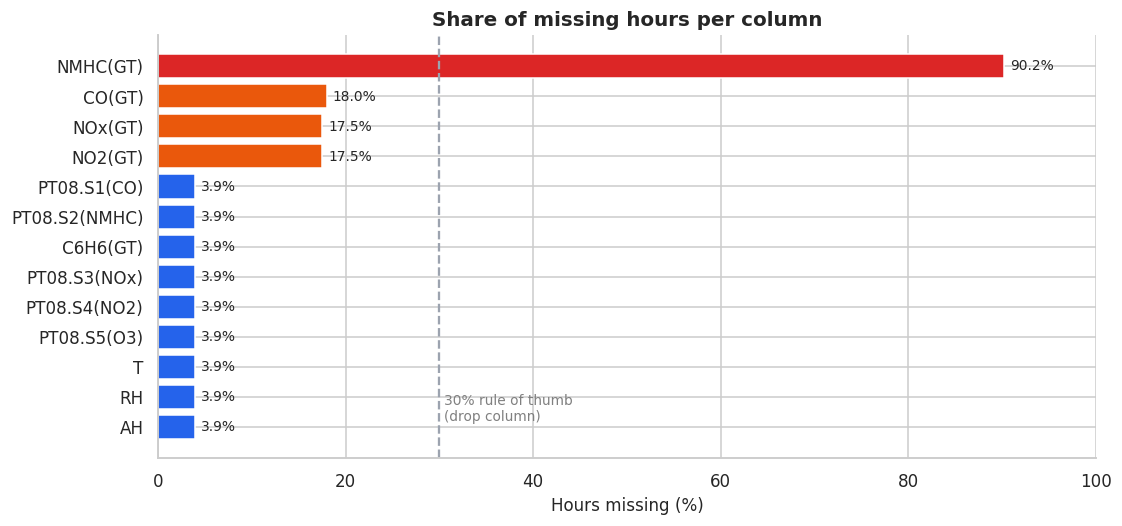

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = [COLORS["red"] if p > 30 else (COLORS["NOx(GT)"] if p > 10 else COLORS["CO(GT)"]) for p in missing["missing_pct"]]
bars = ax.barh(missing.index[::-1], missing["missing_pct"][::-1], color=bar_colors[::-1])
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.axvline(30, ls="--", color=COLORS["grey"]); ax.text(30.5, 0.2, "30% rule of thumb\n(drop column)", color="gray", fontsize=9)
ax.set_xlabel("Hours missing (%)"); ax.set_xlim(0, 100)
ax.set_title("Share of missing hours per column")
savefig("missing_share"); plt.show()

**Three tiers of missingness are visible:**

* `NMHC(GT)` is about 90% missing: the non-methane hydrocarbon analyser was essentially switched off
  after the first few weeks. No imputation can invent 8,400 hours of data, so this column is dropped
  (the course rule of thumb is to drop columns with more than 25–30% missing).
* The three reference pollutants `CO(GT)`, `NOx(GT)` and `NO2(GT)` are each about 18% missing.
* Every sensor and weather column has the same 366 missing hours (3.9%), which suggests the whole
  device was down at the same moments.

Next we check *when* these gaps happen.

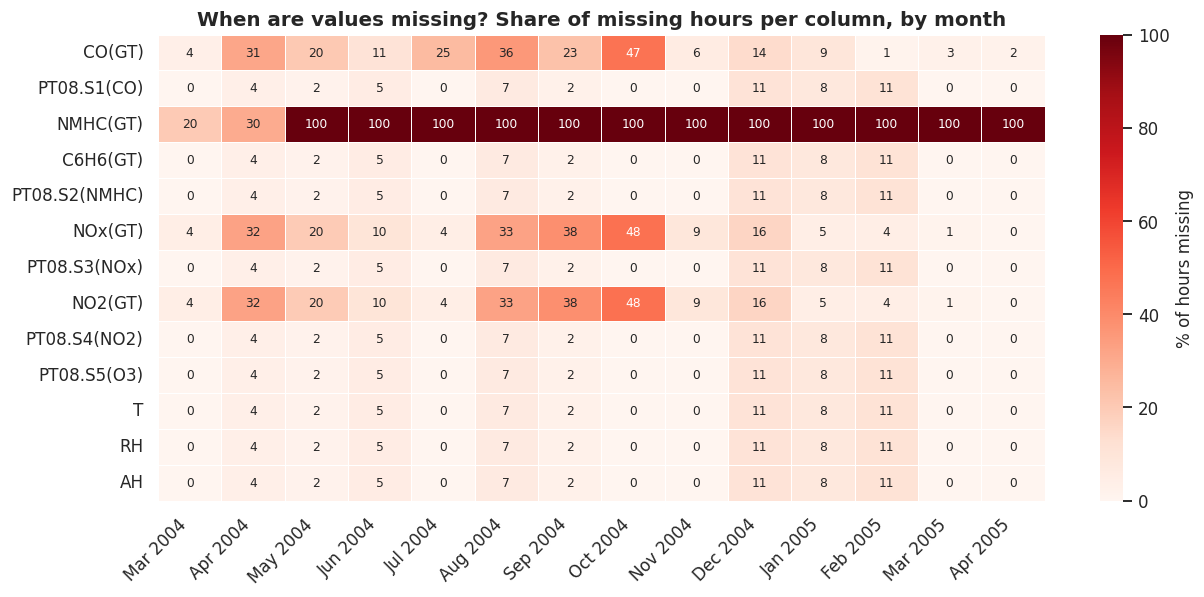

In [8]:
monthly_missing = (df.isna().resample("MS").mean() * 100)
monthly_missing.index = monthly_missing.index.strftime("%b %Y")

fig, ax = plt.subplots(figsize=(13, 5.5))
sns.heatmap(monthly_missing.T, cmap="Reds", vmin=0, vmax=100, annot=True, fmt=".0f",
            annot_kws={"size": 8}, cbar_kws={"label": "% of hours missing"}, linewidths=0.4, ax=ax)
ax.set_title("When are values missing? Share of missing hours per column, by month")
ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=45, ha="right")
savefig("missing_by_month"); plt.show()

**What the heatmap tells us.** The gaps are not random. The NMHC analyser stops almost completely from May 2004 onwards, which settles the decision to drop it. The CO, NOx and NO2 analysers lose between 20% and 48% of their hours in April, August, September and October 2004, so those months will carry less weight in any monthly comparison. The sensor and weather columns share identical missing percentages in every month, confirming that these 366 hours are whole-device outages rather than individual sensor faults. Because the outages affect every input column at the same moments, there is no way to fill them from other columns, which is why we only interpolate short runs.

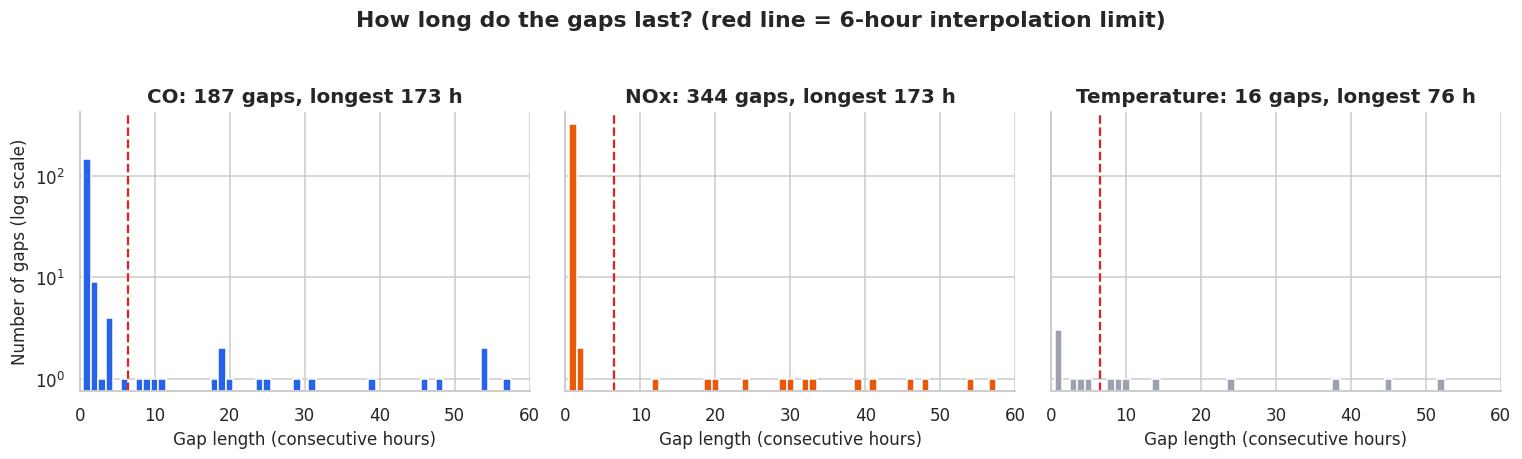

,gaps,share_gaps_≤6h,share_missing_hours_in_gaps_≤6h,longest_gap_h
CO(GT),187.0,85.6,11.2,173.0
NOx(GT),344.0,93.9,19.8,173.0
T,16.0,37.5,4.1,76.0


In [9]:
def gap_lengths(series):
    # Lengths of consecutive runs of NaN, in hours
    is_na = series.isna().astype(int)
    run_id = (is_na.diff() != 0).cumsum()
    runs = is_na.groupby(run_id).agg(["first", "size"])
    return runs.loc[runs["first"] == 1, "size"]

gaps = {c: gap_lengths(df[c]) for c in ["CO(GT)", "NOx(GT)", "T"]}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (c, g) in zip(axes, gaps.items()):
    ax.hist(g, bins=np.arange(0.5, 60.5, 1), color=COLORS.get(c, COLORS["grey"]), edgecolor="white")
    ax.set_yscale("log"); ax.set_xlim(0, 60)
    ax.set_title(f"{LABEL.get(c, c)}: {len(g)} gaps, longest {g.max()} h")
    ax.set_xlabel("Gap length (consecutive hours)")
    ax.axvline(6.5, ls="--", color=COLORS["red"])
axes[0].set_ylabel("Number of gaps (log scale)")
fig.suptitle("How long do the gaps last? (red line = 6-hour interpolation limit)", fontweight="bold", y=1.04)
plt.tight_layout(); savefig("gap_lengths"); plt.show()

gap_summary = pd.DataFrame({c: {"gaps": len(g), "share_gaps_≤6h": round((g <= 6).mean() * 100, 1),
                               "share_missing_hours_in_gaps_≤6h": round(g[g <= 6].sum() / g.sum() * 100, 1),
                               "longest_gap_h": int(g.max())} for c, g in gaps.items()}).T
gap_summary

**What the gap lengths tell us.** For CO, 86% of the 187 gaps are six hours or shorter, but those short gaps hold only 11% of the missing hours; the rest sit in a handful of long outages, the longest lasting 173 hours (about a week). Temperature has just 16 gaps, and most are long blocks, so interpolation will fill only a small fraction of its 366 missing hours. The histogram justifies the six-hour limit: inside that window the readings on either side are close enough in time to draw a straight line between, while a week-long outage would be pure guesswork.

### 2.1 Our documented imputation strategy

| Column(s) | Missing | Decision | Reason |
|---|---|---|---|
| `NMHC(GT)` | ~90% | **Drop the column** | Nothing to interpolate from; any fill would be fiction. |
| `CO(GT)` (our target) | ~18% | **Never impute.** Rows without a target are excluded from modelling only. | Imputing the target would mean training the model on values we made up. |
| `NOx(GT)`, `NO2(GT)`, `C6H6(GT)` | 4–18% | Keep as `NaN` for the visualisations (averages simply skip them). Not used as model inputs. | A city would not have reference NOx readings if it lacked reference CO readings, so they are not fair predictors. |
| `T`, `RH`, `AH`, `PT08.S1`–`S5` | ~4% | **Time-based linear interpolation, up to 6 consecutive hours.** Longer gaps stay `NaN` and those hours are excluded from modelling. | Weather and sensor responses change smoothly hour to hour, so a straight line between neighbours is a good estimate for short gaps. Beyond 6 hours a whole diurnal cycle could be missed. |

The 6-hour limit comes from the gap-length histogram above: almost all gaps are short, and the few long
outages are not worth guessing at.

## 3. Cleaning and imputation

We now apply the strategy above and then check that it did not distort the data.

In [10]:
df = df.drop(columns=["NMHC(GT)"])
INTERP_COLS = WEATHER + SENSORS
before = df[INTERP_COLS].copy()

def fill_short_gaps(s, max_gap=6):
    # Interpolate linearly in time, but only inside runs of NaN that are max_gap hours or shorter.
    # (pandas' own `limit=` argument fills the first n values of *every* gap, which is not the rule we documented.)
    na = s.isna()
    run_len = na.groupby((na != na.shift()).cumsum()).transform("size")
    return s.interpolate(method="time", limit_area="inside").mask(na & (run_len > max_gap))

df[INTERP_COLS] = df[INTERP_COLS].apply(fill_short_gaps)

filled = before.isna().sum() - df[INTERP_COLS].isna().sum()
report = pd.DataFrame({"missing_before": before.isna().sum(), "filled_by_interpolation": filled,
                       "still_missing_(gaps_longer_than_6h)": df[INTERP_COLS].isna().sum()})
report

,missing_before,filled_by_interpolation,still_missing_(gaps_longer_than_6h)
T,366,15,351
RH,366,15,351
AH,366,15,351
PT08.S1(CO),366,15,351
PT08.S2(NMHC),366,15,351
PT08.S3(NOx),366,15,351
PT08.S4(NO2),366,15,351
PT08.S5(O3),366,15,351


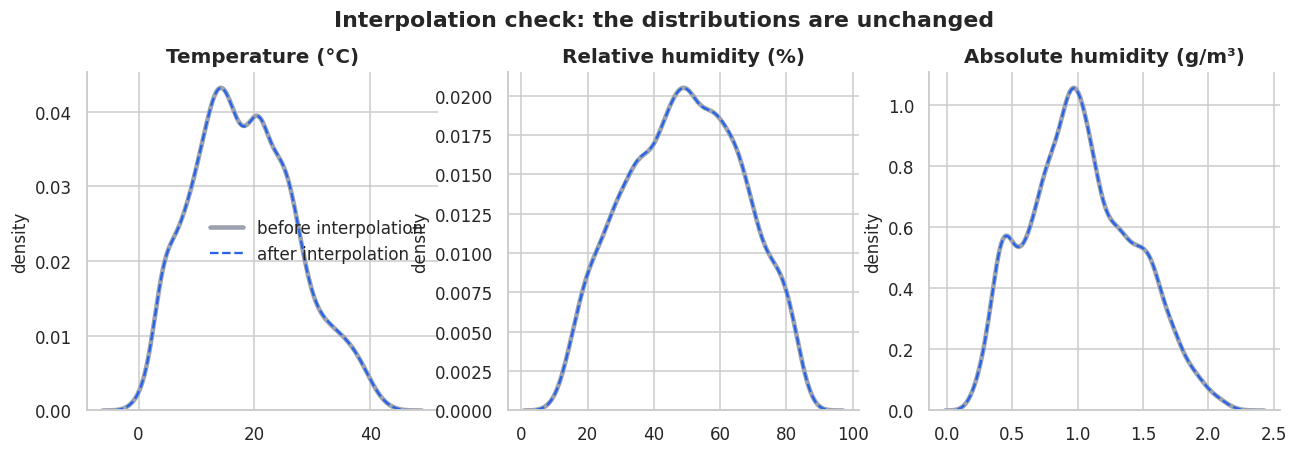

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, WEATHER):
    sns.kdeplot(before[c].dropna(), ax=ax, color=COLORS["grey"], lw=3, label="before interpolation")
    sns.kdeplot(df[c].dropna(), ax=ax, color=COLORS["CO(GT)"], lw=1.5, ls="--", label="after interpolation")
    ax.set_title(label(c)); ax.set_xlabel(""); ax.set_ylabel("density")
axes[0].legend()
fig.suptitle("Interpolation check: the distributions are unchanged", fontweight="bold", y=1.02)
savefig("interpolation_check"); plt.show()

The dashed line sits exactly on the solid one for all three weather variables, so the interpolation did
not shift the distributions. Note how few hours were actually filled: the table above shows that most of
the 366 weather and sensor outages come in long blocks (the device was down for days at a time), and
those stay as `NaN` by design. That is what we want from an imputation step: the short holes are closed,
the long ones are not invented, and the data looks the same.

### 3.1 Outliers: flag them, understand them, keep the real ones

Pollution data has genuine spikes, and those spikes are exactly the events a city cares about. We
therefore **do not delete statistical outliers**. We only remove values that are physically impossible.

In [12]:
check_cols = POLLUTANTS + WEATHER
q1, q3 = df[check_cols].quantile(0.25), df[check_cols].quantile(0.75)
iqr = q3 - q1
outlier_flags = pd.DataFrame({
    "IQR_outliers_high": ((df[check_cols] > q3 + 1.5 * iqr)).sum(),
    "IQR_outliers_low": ((df[check_cols] < q1 - 1.5 * iqr)).sum(),
    "min": df[check_cols].min().round(2), "max": df[check_cols].max().round(2),
})
impossible = {"negative concentrations": int((df[POLLUTANTS] < 0).sum().sum()),
              "RH outside 0–100%": int(((df["RH"] < 0) | (df["RH"] > 100)).sum()),
              "AH negative": int((df["AH"] < 0).sum())}
print("Physically impossible values:", impossible)
outlier_flags

Physically impossible values: {'negative concentrations': 0, 'RH outside 0–100%': 0, 'AH negative': 0}


,IQR_outliers_high,IQR_outliers_low,min,max
CO(GT),215,0,0.10,11.90
NOx(GT),435,0,2.00,1479.00
NO2(GT),107,0,2.00,340.00
C6H6(GT),228,0,0.10,63.70
T,3,0,-1.90,44.60
RH,0,0,9.20,88.70
AH,2,0,0.18,2.23


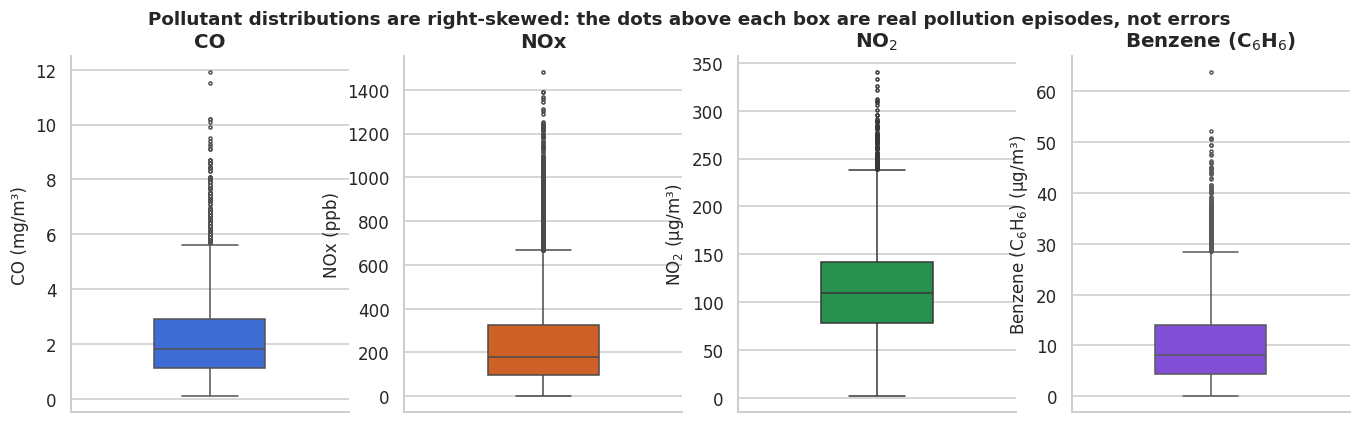

Clean hourly table saved → clean_hourly.csv  shape: (9357, 12)


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, c in zip(axes, POLLUTANTS):
    sns.boxplot(y=df[c].dropna(), ax=ax, color=COLORS[c], width=0.4, fliersize=2)
    ax.set_ylabel(label(c)); ax.set_title(LABEL[c])
fig.suptitle("Pollutant distributions are right-skewed: the dots above each box are real pollution episodes, not errors",
             fontweight="bold", fontsize=12)
savefig("outlier_boxplots"); plt.show()

clean = df.copy()
clean.to_csv("clean_hourly.csv")
print("Clean hourly table saved → clean_hourly.csv  shape:", clean.shape)

No physically impossible values exist, so nothing is removed. The IQR rule flags a few hundred high
hours per pollutant, but a boxplot of a skewed variable always does that. Those hours are the winter
evening traffic peaks we will see in the next section, and they stay in.

## 4. Exploratory analysis: how pollution changes over time

Pollution does not behave uniformly. The brief asks us to understand the patterns, not just describe
them, so every chart here is paired with a statistical test or a number a planner could use.

### 4.1 The full year, four pollutants (time-based visualisation)

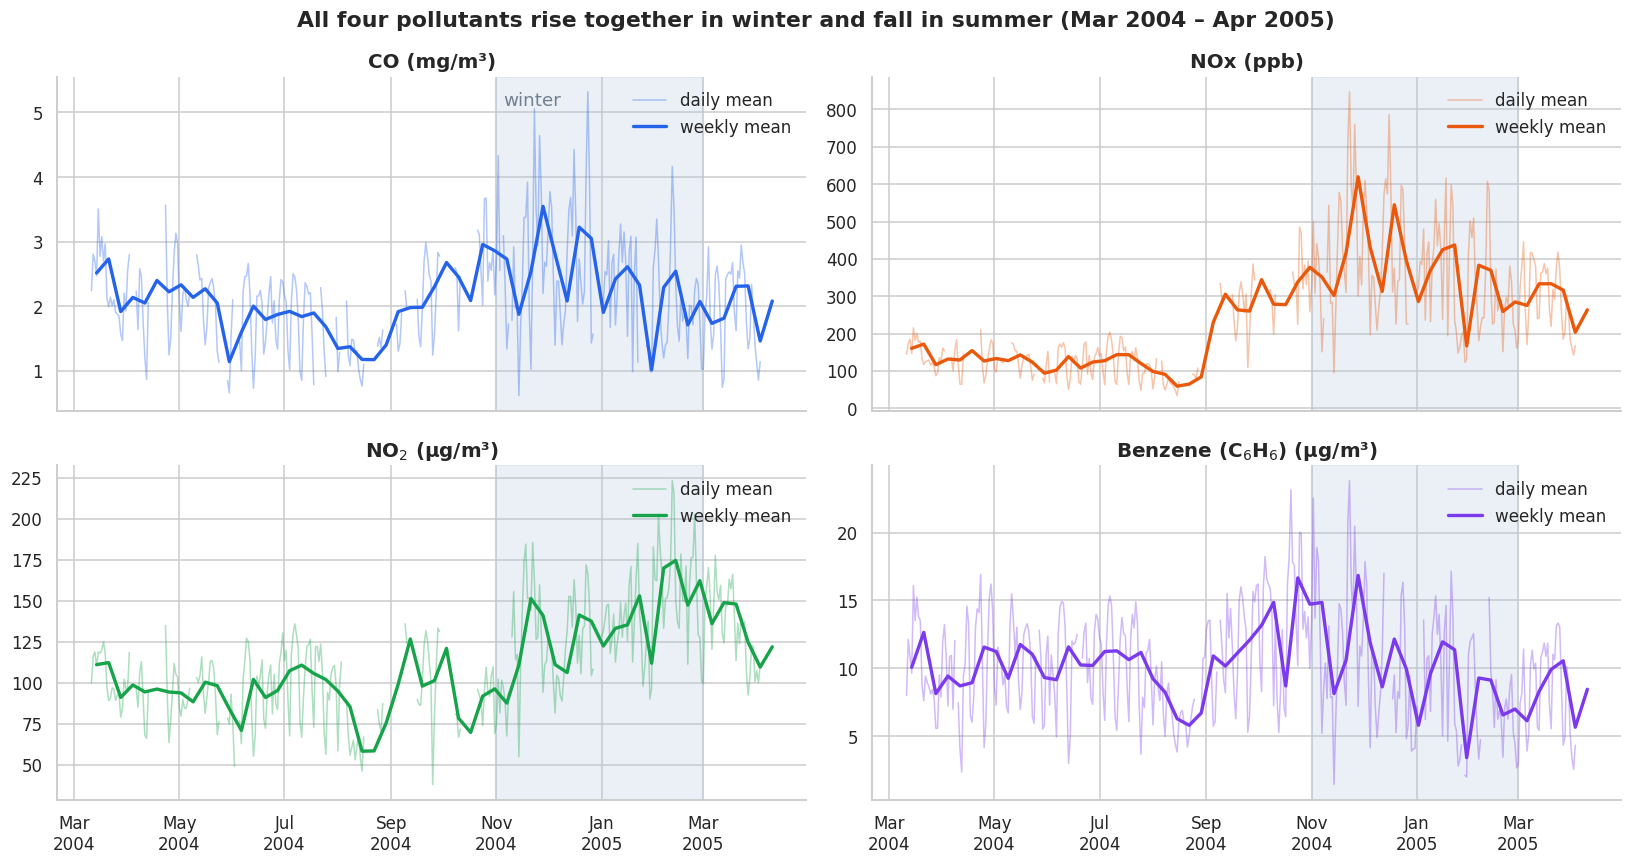

In [14]:
# A day only counts if at least 18 of its 24 hours were measured (the usual 75% data-capture rule)
daily = df[POLLUTANTS].resample("D").mean().where(df[POLLUTANTS].resample("D").count() >= 18)
weekly = df[POLLUTANTS].resample("W").mean()

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for ax, c in zip(axes.ravel(), POLLUTANTS):
    ax.plot(daily.index, daily[c], color=COLORS[c], alpha=0.35, lw=1, label="daily mean")
    ax.plot(weekly.index, weekly[c], color=COLORS[c], lw=2.2, label="weekly mean")
    ax.set_title(label(c)); ax.legend(loc="upper right")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    # shade the winter heating season
    ax.axvspan(pd.Timestamp("2004-11-01"), pd.Timestamp("2005-03-01"), color="lightsteelblue", alpha=0.25)
axes[0, 0].text(pd.Timestamp("2004-11-05"), axes[0, 0].get_ylim()[1] * 0.92, "winter", color="slategray")
fig.suptitle("All four pollutants rise together in winter and fall in summer (Mar 2004 – Apr 2005)", fontweight="bold")
plt.tight_layout(); savefig("yearly_trends"); plt.show()

**What the year looks like.** All four pollutants share one seasonal shape: lowest in July and August, rising sharply from September, peaking between October and December, then easing through spring. Monthly mean CO runs from 1.28 mg/m³ in August 2004 to 2.75 mg/m³ in December 2004, more than double. NOx shows the strongest swing of all, from weekly means below 60 ppb in late summer to above 600 ppb in November. Two things drive this: winter heating adds emissions, and cold, still winter air traps them near the ground. The fact that the pollutants move together also tells us they come from the same source mix, mainly road traffic at this roadside site.

### 4.2 Which hours of the day are worst, and are weekends different?

We overlay the average day for weekdays and weekends. The shaded band is the interquartile range, so it
shows how variable each hour is, not just its average.

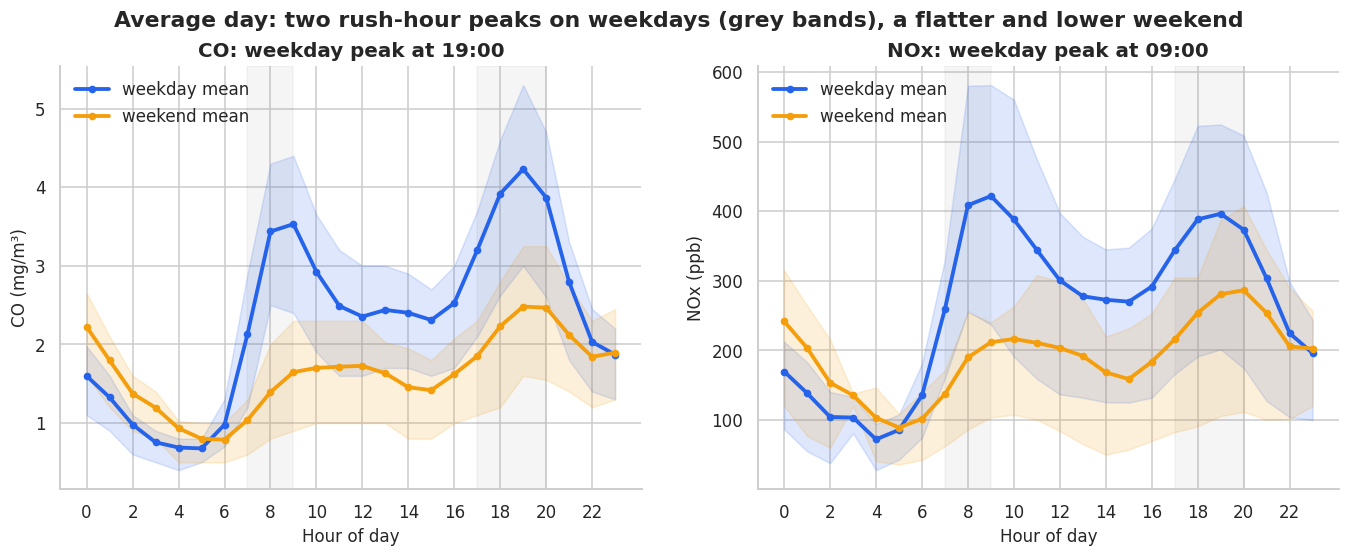

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
daytype,,,,,,,,,,,,,,,,,,,,,
weekday,1.60,1.32,0.98,0.75,0.69,0.68,0.98,2.13,3.44,3.53,...,2.40,2.31,2.53,3.20,3.92,4.23,3.87,2.79,2.03,1.87
weekend,2.22,1.80,1.37,1.19,0.93,0.80,0.79,1.04,1.39,1.65,...,1.45,1.42,1.62,1.85,2.23,2.48,2.47,2.12,1.84,1.90
weekend_vs_weekday_%,39.00,36.00,40.00,59.00,35.00,18.00,-19.00,-51.00,-60.00,-53.00,...,-40.00,-39.00,-36.00,-42.00,-43.00,-41.00,-36.00,-24.00,-9.00,2.00


In [15]:
prof = df[["CO(GT)", "NOx(GT)"]].copy()
prof["hour"] = prof.index.hour
prof["daytype"] = np.where(prof.index.dayofweek >= 5, "weekend", "weekday")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, c in zip(axes, ["CO(GT)", "NOx(GT)"]):
    for dt in ["weekday", "weekend"]:
        g = prof[prof["daytype"] == dt].groupby("hour")[c]
        m, lo, hi = g.mean(), g.quantile(0.25), g.quantile(0.75)
        ax.plot(m.index, m, color=COLORS[dt], lw=2.5, marker="o", ms=4, label=f"{dt} mean")
        ax.fill_between(m.index, lo, hi, color=COLORS[dt], alpha=0.15)
    peak_h = prof[prof["daytype"] == "weekday"].groupby("hour")[c].mean().idxmax()
    ax.axvspan(7, 9, color="gray", alpha=0.08); ax.axvspan(17, 20, color="gray", alpha=0.08)
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day"); ax.set_ylabel(label(c))
    ax.set_title(f"{LABEL[c]}: weekday peak at {peak_h:02d}:00")
    ax.legend(loc="upper left")
fig.suptitle("Average day: two rush-hour peaks on weekdays (grey bands), a flatter and lower weekend", fontweight="bold")
savefig("hourly_profile"); plt.show()

hourly_table = prof.groupby(["daytype", "hour"])["CO(GT)"].mean().unstack(0).round(2)
hourly_table["weekend_vs_weekday_%"] = ((hourly_table["weekend"] / hourly_table["weekday"] - 1) * 100).round(0)
hourly_table.T

**What the average day tells us.** Weekdays have two clear peaks, a morning one around 08:00 to 09:00 and a larger evening one at 19:00, when mean CO reaches 3.7 mg/m³ compared with 0.7 mg/m³ at 05:00. These are commuting hours, which is the strongest evidence in the data that traffic is the main source. Weekends are different in shape, not just in level: the morning peak almost disappears (weekend CO at 08:00 is 60% lower than on weekdays) and the evening peak is smaller and later. Between midnight and 04:00 the order flips and weekends are actually 35% to 60% higher, which fits late-night social traffic on Friday and Saturday nights. For a city this means a single daily limit hides the real problem: the harm is concentrated in roughly six weekday hours.

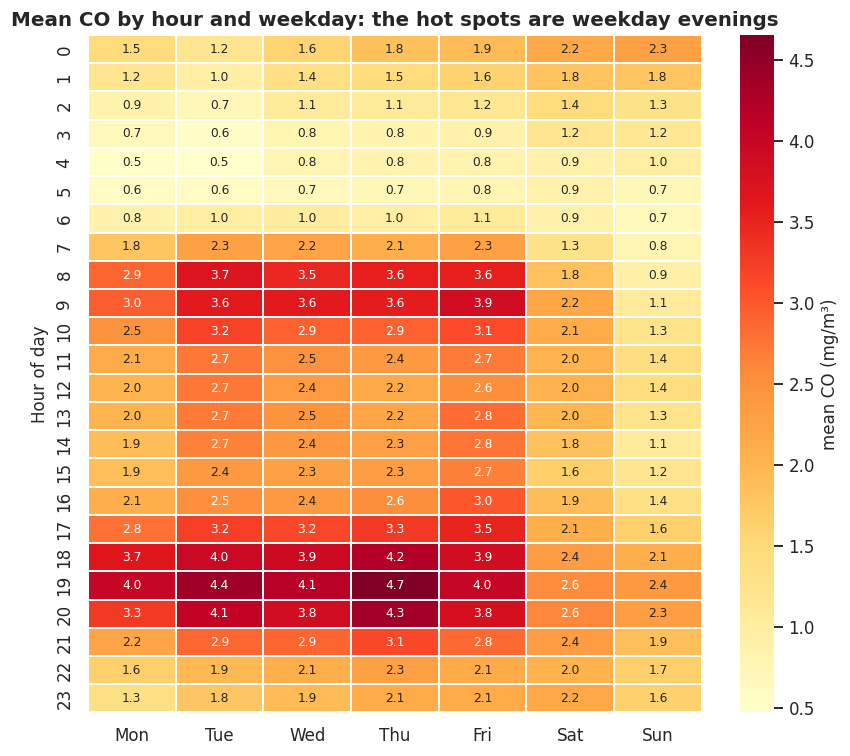

In [16]:
heat = df[["CO(GT)"]].copy()
heat["hour"] = heat.index.hour; heat["dow"] = heat.index.dayofweek
pivot = heat.pivot_table(values="CO(GT)", index="hour", columns="dow", aggfunc="mean")
pivot.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".1f", annot_kws={"size": 8},
            cbar_kws={"label": "mean CO (mg/m³)"}, linewidths=0.3, ax=ax)
ax.set_title("Mean CO by hour and weekday: the hot spots are weekday evenings")
ax.set_xlabel(""); ax.set_ylabel("Hour of day")
savefig("heatmap_hour_dow"); plt.show()

### 4.3 Seasonality

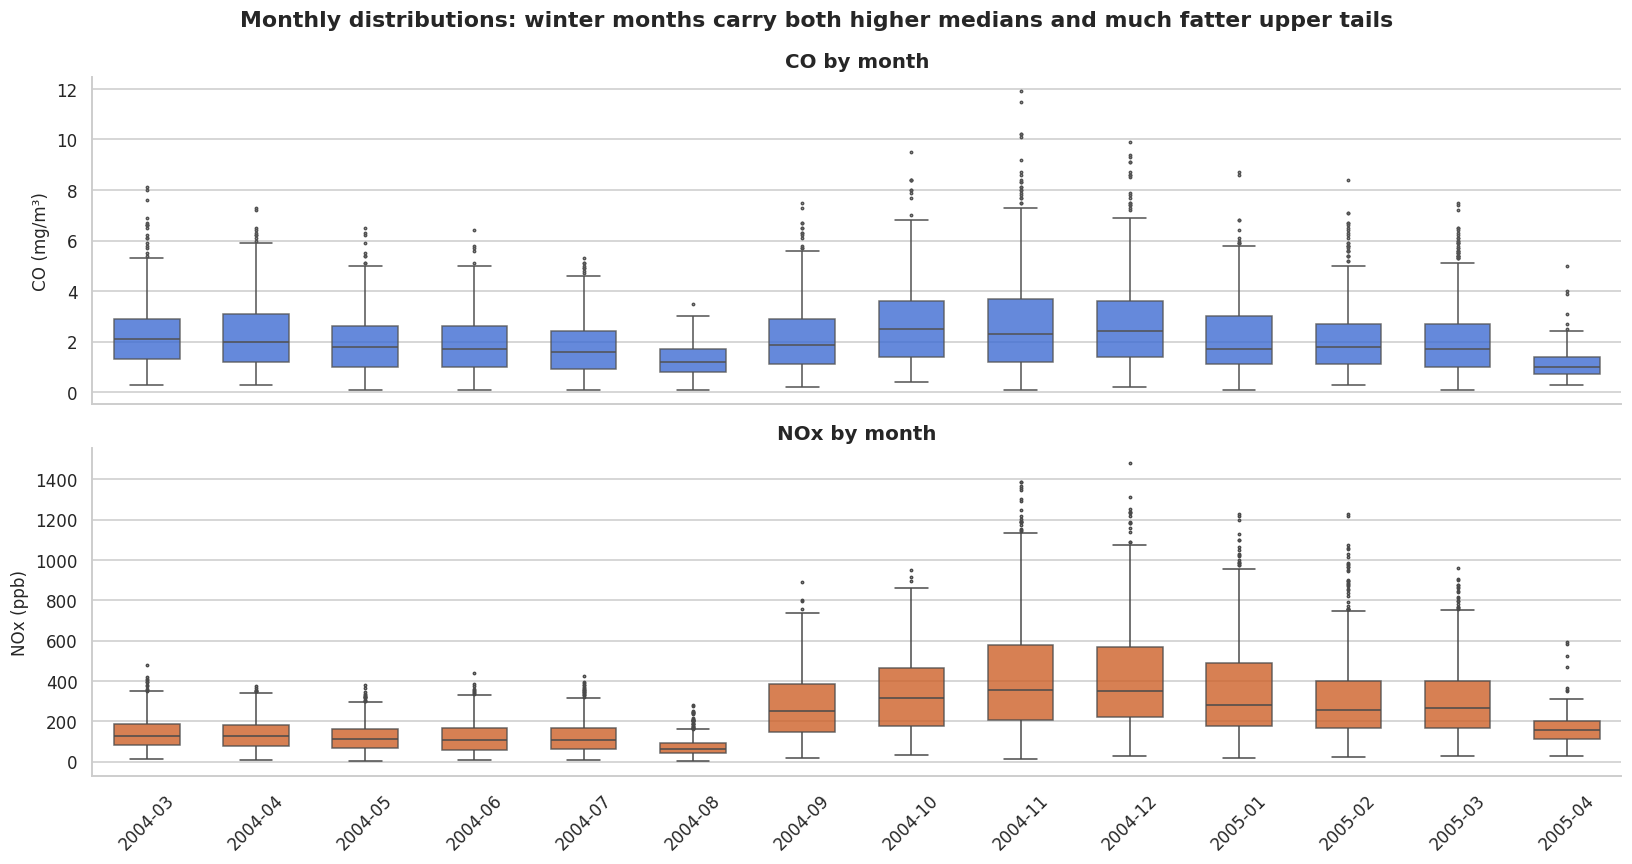

In [17]:
season_df = df[["CO(GT)", "NOx(GT)"]].copy()
season_df["month"] = season_df.index.strftime("%Y-%m")
order = sorted(season_df["month"].unique())

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, c in zip(axes, ["CO(GT)", "NOx(GT)"]):
    sns.boxplot(data=season_df, x="month", y=c, order=order, color=COLORS[c], fliersize=1.5,
                width=0.6, ax=ax, boxprops={"alpha": 0.8})
    ax.set_ylabel(label(c)); ax.set_xlabel(""); ax.set_title(f"{LABEL[c]} by month")
plt.xticks(rotation=45)
fig.suptitle("Monthly distributions: winter months carry both higher medians and much fatter upper tails", fontweight="bold")
plt.tight_layout(); savefig("monthly_boxplots"); plt.show()

### 4.4 Weather: does humidity or temperature suppress pollution?

The brief asks whether **rainfall suppresses particulate matter**. This dataset has neither a rainfall
gauge nor a particulate-matter analyser, so that exact question cannot be answered here (we return to
this in the limitations). What we *can* test is the closest available version: how CO responds to
temperature and to humidity. Each panel shows the mean CO inside equal-width bins of the weather
variable, with 95% confidence intervals.

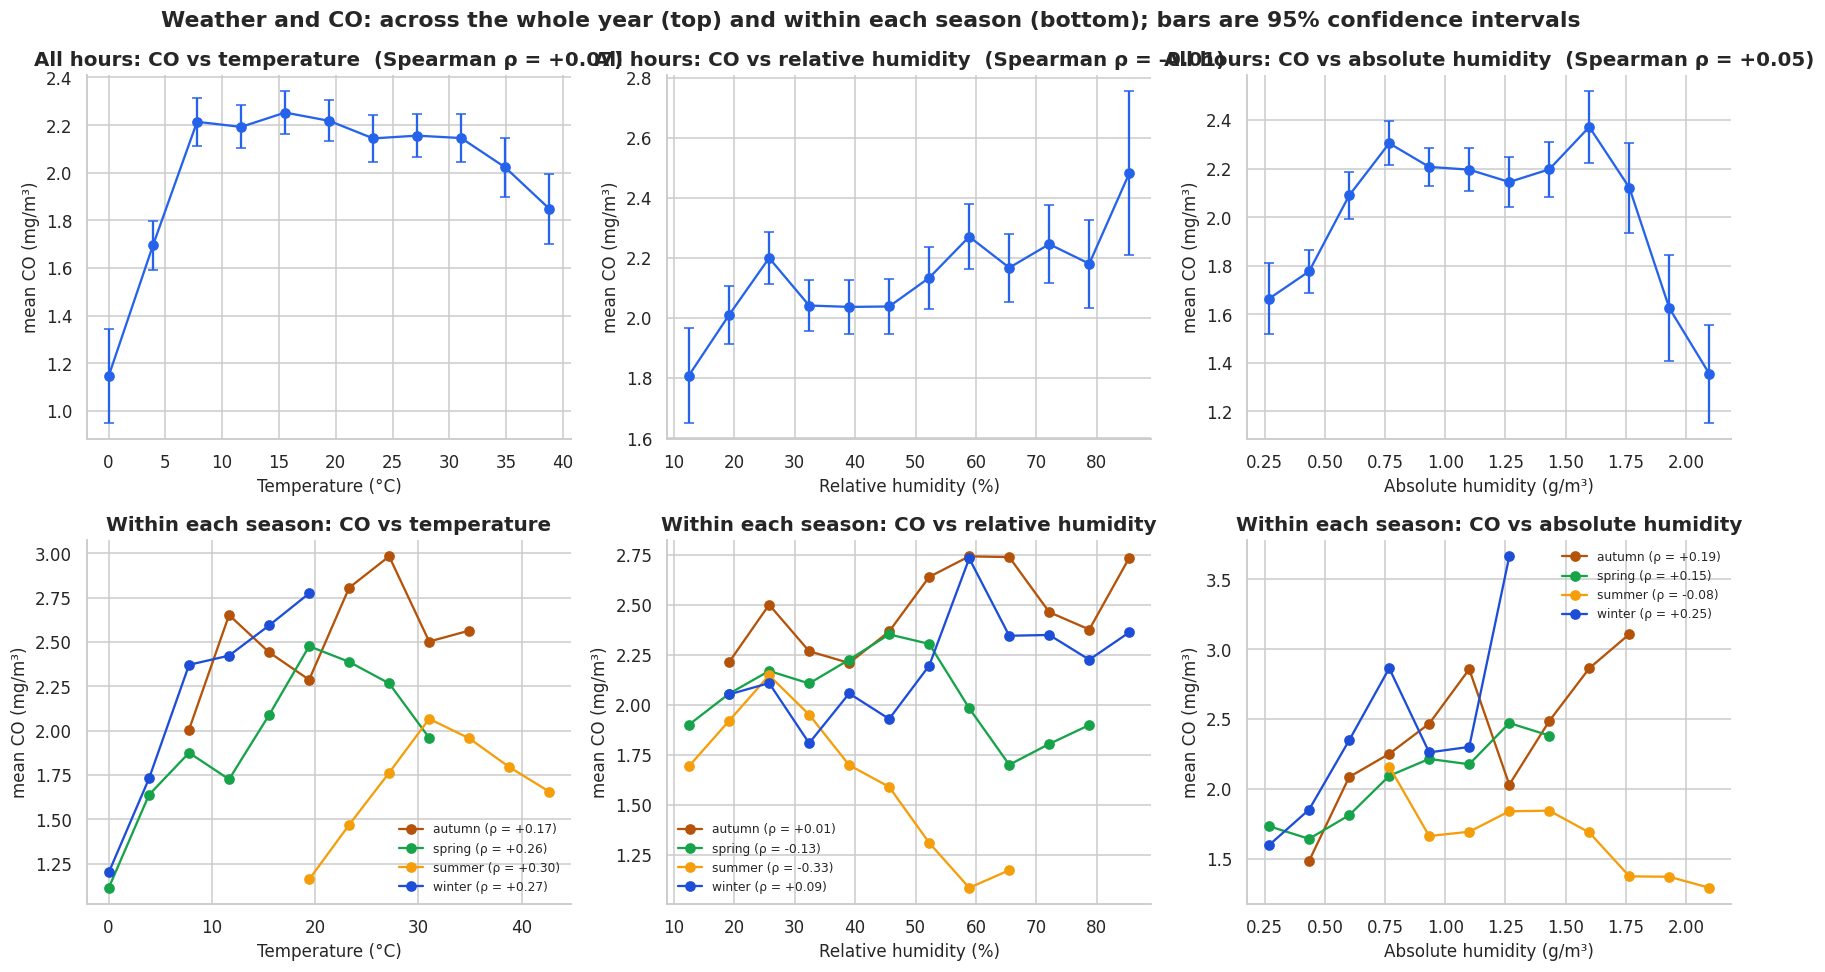

In [18]:
season_of = lambda idx: pd.Series(idx.month, index=idx).map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                                                             6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"})
SEASON_COLORS = {"winter": "#1d4ed8", "spring": "#16a34a", "summer": "#f59e0b", "autumn": "#b45309"}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, w in enumerate(WEATHER):
    tmp = df[[TARGET, w]].dropna().copy()
    tmp["bin"] = pd.cut(tmp[w], bins=12)
    tmp["season"] = season_of(tmp.index)
    # top row: raw relationship across the whole year
    ax = axes[0, j]
    g = tmp.groupby("bin", observed=True)[TARGET].agg(["mean", "sem", "count"]); g = g[g["count"] >= 30]
    ax.errorbar([b.mid for b in g.index], g["mean"], yerr=1.96 * g["sem"], fmt="o-", color=COLORS["CO(GT)"], capsize=3)
    rho, p = stats.spearmanr(tmp[w], tmp[TARGET])
    ax.set_title(f"All hours: CO vs {LABEL[w].lower()}  (Spearman ρ = {rho:+.2f})"); ax.set_xlabel(label(w)); ax.set_ylabel("mean CO (mg/m³)")
    # bottom row: the same relationship inside each season (removes the winter-is-cold-and-dirty confound)
    ax = axes[1, j]
    for s, g_s in tmp.groupby("season"):
        g = g_s.groupby("bin", observed=True)[TARGET].agg(["mean", "count"]); g = g[g["count"] >= 25]
        if len(g) > 2:
            rho_s = stats.spearmanr(g_s[w], g_s[TARGET])[0]
            ax.plot([b.mid for b in g.index], g["mean"], "o-", color=SEASON_COLORS[s], label=f"{s} (ρ = {rho_s:+.2f})")
    ax.set_title(f"Within each season: CO vs {LABEL[w].lower()}"); ax.set_xlabel(label(w)); ax.set_ylabel("mean CO (mg/m³)"); ax.legend(fontsize=8)
fig.suptitle("Weather and CO: across the whole year (top) and within each season (bottom); bars are 95% confidence intervals",
             fontweight="bold")
plt.tight_layout(); savefig("weather_vs_co"); plt.show()

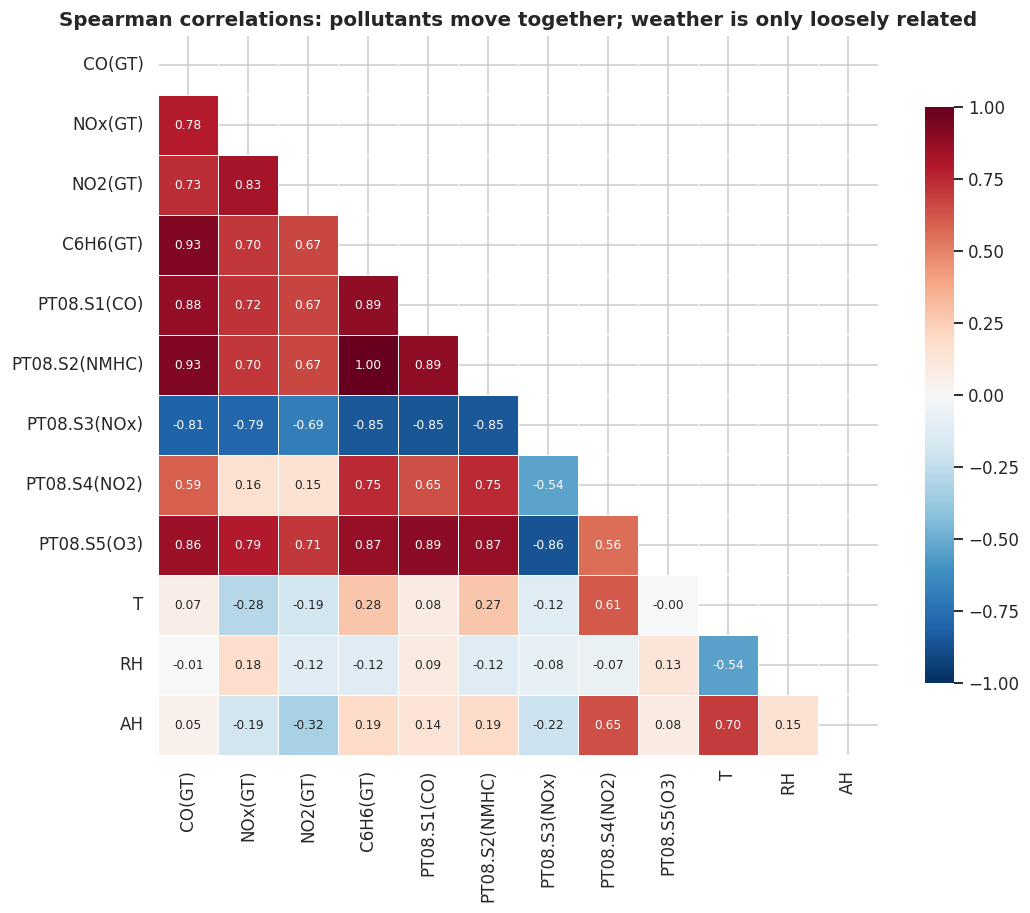

In [19]:
corr = df[POLLUTANTS + SENSORS + WEATHER].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, square=True, linewidths=0.4, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlations: pollutants move together; weather is only loosely related")
savefig("correlation_heatmap"); plt.show()

**What the weather plots tell us.** Taken across the whole year, temperature and humidity are poor predictors of CO on their own: the Spearman correlations are +0.07 for temperature, -0.01 for relative humidity and +0.05 for absolute humidity. The binned means are not flat, though. The coldest hours (below 5 °C) are the cleanest, which is the opposite of what a simple winter-is-dirty story would predict, because those are mostly night-time hours with no traffic. Within a single season the relationships are modest and non-linear, with correlations between about 0.1 and 0.3. The correlation heatmap confirms the picture: the pollutants are strongly correlated with each other (CO with benzene at 0.93, with NOx at 0.78), while the weather variables sit close to zero with all of them. In short, at this site *when* it is matters far more than *what the weather is*, and the weather effects that do exist are tangled up with the time of day. Section 8 separates them.

### 4.5 Sensor drift: why sensor data is only a proxy for air quality

The cheap `PT08.S1(CO)` sensor is supposed to track the certified `CO(GT)` analyser. If the sensor
were perfect the correlation between them would be the same every month. We compute it month by month.

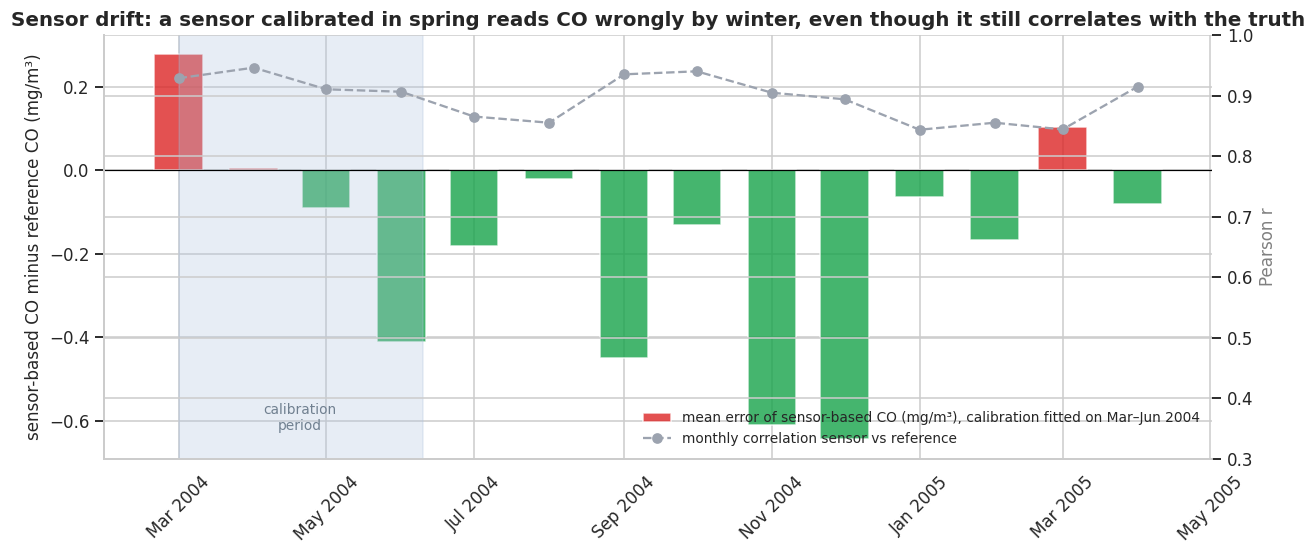

,pearson_r,mean_calibration_error,rmse_calibration,n
month,,,,
2004-03-01,0.929,0.277,0.573,492
2004-04-01,0.946,0.004,0.474,471
2004-05-01,0.910,-0.092,0.511,592
2004-06-01,0.906,-0.412,0.665,607
2004-07-01,0.865,-0.182,0.593,558
2004-08-01,0.855,-0.022,0.315,432
2004-09-01,0.935,-0.449,0.737,555
2004-10-01,0.940,-0.132,0.653,393
2004-11-01,0.905,-0.610,1.069,679


In [20]:
# Calibrate the cheap sensor on its first three months, then see how far its predictions drift afterwards.
pair = df[["PT08.S1(CO)", "CO(GT)"]].dropna()
calib = pair.loc[: "2004-06-10"]
slope, intercept = np.polyfit(calib["PT08.S1(CO)"], calib["CO(GT)"], 1)
pair["co_from_sensor"] = intercept + slope * pair["PT08.S1(CO)"]
pair["calibration_error"] = pair["co_from_sensor"] - pair["CO(GT)"]

drift = []
for period, g in pair.groupby(pair.index.to_period("M")):
    if len(g) > 50:
        drift.append({"month": period.to_timestamp(), "pearson_r": g["PT08.S1(CO)"].corr(g["CO(GT)"]),
                      "mean_calibration_error": g["calibration_error"].mean(),
                      "rmse_calibration": np.sqrt((g["calibration_error"] ** 2).mean()), "n": len(g)})
drift = pd.DataFrame(drift).set_index("month")

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(drift.index, drift["mean_calibration_error"], width=20, color=[COLORS["red"] if v > 0 else COLORS["NO2(GT)"] for v in drift["mean_calibration_error"]],
        alpha=0.8, label="mean error of sensor-based CO (mg/m³), calibration fitted on Mar–Jun 2004")
ax1.axhline(0, color="black", lw=0.8); ax1.axvspan(pd.Timestamp("2004-03-01"), pd.Timestamp("2004-06-10"), color="lightsteelblue", alpha=0.3)
ax1.text(pd.Timestamp("2004-04-20"), ax1.get_ylim()[0] * 0.9, "calibration\nperiod", color="slategray", fontsize=9, ha="center")
ax1.set_ylabel("sensor-based CO minus reference CO (mg/m³)")
ax2 = ax1.twinx()
ax2.plot(drift.index, drift["pearson_r"], marker="o", color=COLORS["grey"], lw=1.5, ls="--", label="monthly correlation sensor vs reference")
ax2.set_ylabel("Pearson r", color="gray"); ax2.set_ylim(0.3, 1.0)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); plt.setp(ax1.get_xticklabels(), rotation=45)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=9)
ax1.set_title("Sensor drift: a sensor calibrated in spring reads CO wrongly by winter, even though it still correlates with the truth")
savefig("sensor_drift"); plt.show()
drift.round(3)

**What the drift chart tells us.** The cheap CO sensor stays well correlated with the reference analyser all year (monthly r between 0.84 and 0.95), but correlation is not accuracy. A linear calibration fitted on the first three months reads 0.4 to 0.65 mg/m³ too low from June onwards and by November and December under-reads by about 0.6 mg/m³, roughly 20% of the winter mean. This is the classic behaviour of metal-oxide sensors: their response to the gas changes with temperature, humidity and age. A city that deployed such sensors once calibrated and then trusted them would systematically under-report winter pollution, exactly when it matters most. Sensor readings are a proxy for air quality, and the proxy moves.

### 4.6 Putting numbers on the patterns: statistical tests

Charts suggest; tests confirm. We use non-parametric tests because pollution data is skewed.

In [21]:
daily_co = df[TARGET].resample("D").agg(["mean", "count"]).query("count >= 18")["mean"].to_frame("co")
daily_co["weekend"] = daily_co.index.dayofweek >= 5
wd, we = daily_co.loc[~daily_co["weekend"], "co"], daily_co.loc[daily_co["weekend"], "co"]
u, p_u = stats.mannwhitneyu(wd, we, alternative="two-sided")

hourly_groups = [g.dropna().values for _, g in df[TARGET].groupby(df.index.hour)]
h_stat, p_h = stats.kruskal(*hourly_groups)

monthly_groups = [g.dropna().values for _, g in df[TARGET].groupby(df.index.month)]
m_stat, p_m = stats.kruskal(*monthly_groups)

rows = [
    {"question": "Weekdays vs weekends (daily mean CO)", "test": "Mann-Whitney U", "statistic": round(u), "p_value": p_u,
     "effect": f"weekday {wd.mean():.2f} vs weekend {we.mean():.2f} mg/m³ ({(we.mean()/wd.mean()-1)*100:+.0f}%)"},
    {"question": "Does hour of day matter?", "test": "Kruskal-Wallis (24 groups)", "statistic": round(h_stat), "p_value": p_h,
     "effect": f"worst hour {df[TARGET].groupby(df.index.hour).mean().idxmax():02d}:00 = {df[TARGET].groupby(df.index.hour).mean().max():.2f}, best {df[TARGET].groupby(df.index.hour).mean().idxmin():02d}:00 = {df[TARGET].groupby(df.index.hour).mean().min():.2f} mg/m³"},
    {"question": "Does month matter?", "test": "Kruskal-Wallis (12 groups)", "statistic": round(m_stat), "p_value": p_m,
     "effect": f"worst month {df[TARGET].groupby(df.index.month).mean().idxmax()} = {df[TARGET].groupby(df.index.month).mean().max():.2f} mg/m³"},
]
for w in WEATHER:
    tmp = df[[TARGET, w]].dropna(); rho, p = stats.spearmanr(tmp[w], tmp[TARGET])
    rows.append({"question": f"CO vs {LABEL[w].lower()}", "test": "Spearman correlation", "statistic": round(rho, 3), "p_value": p,
                 "effect": "negative: cleaner when higher" if rho < 0 else "positive: dirtier when higher"})
tests = pd.DataFrame(rows)
tests["p_value"] = tests["p_value"].apply(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
tests

,question,test,statistic,p_value,effect
0,Weekdays vs weekends (daily mean CO),Mann-Whitney U,16106.000,< 0.001,weekday 2.36 vs weekend 1.66 mg/m³ (-30%)
1,Does hour of day matter?,Kruskal-Wallis (24 groups),2968.000,< 0.001,"worst hour 19:00 = 3.73, best 05:00 = 0.71 mg/m³"
2,Does month matter?,Kruskal-Wallis (12 groups),426.000,< 0.001,worst month 12 = 2.75 mg/m³
3,CO vs temperature,Spearman correlation,0.068,< 0.001,positive: dirtier when higher
4,CO vs relative humidity,Spearman correlation,-0.006,0.629,negative: cleaner when higher
5,CO vs absolute humidity,Spearman correlation,0.052,< 0.001,positive: dirtier when higher


**What the tests tell us.** All three time effects are statistically significant (p < 0.001) and, more importantly, large: weekday daily means are 2.36 mg/m³ against 1.66 mg/m³ at weekends, a 30% drop; the worst hour (19:00) averages five times the best hour (05:00); and December averages more than double August. The weather correlations are tiny: temperature and absolute humidity are statistically significant only because there are more than 7,000 observations, and relative humidity is not significant at all. The practical reading is that a planner can predict a dirty hour from the clock and the calendar with far more confidence than from the forecast.

### 4.7 How often are legal limits breached? (the numbers the policy section needs)

Two official thresholds apply to the pollutants we have:

* **CO:** EU limit value of **10 mg/m³ as a maximum daily 8-hour mean** (Directive 2008/50/EC). The WHO
  2021 guideline is stricter at 4 mg/m³ for a 24-hour mean.
* **NO₂:** EU hourly limit of **200 µg/m³**.

,hours_exceeding,days_with_any_exceedance,share_of_observed_hours_%
CO 8-h mean > 10 mg/m³ (EU),0,0,0.0
CO 24-h mean > 4 mg/m³ (WHO),166,15,2.2
NO2 hourly > 200 µg/m³ (EU),386,87,5.0


Benzene annual mean = 10.08 µg/m³ vs EU annual limit 5 µg/m³  →  EXCEEDED


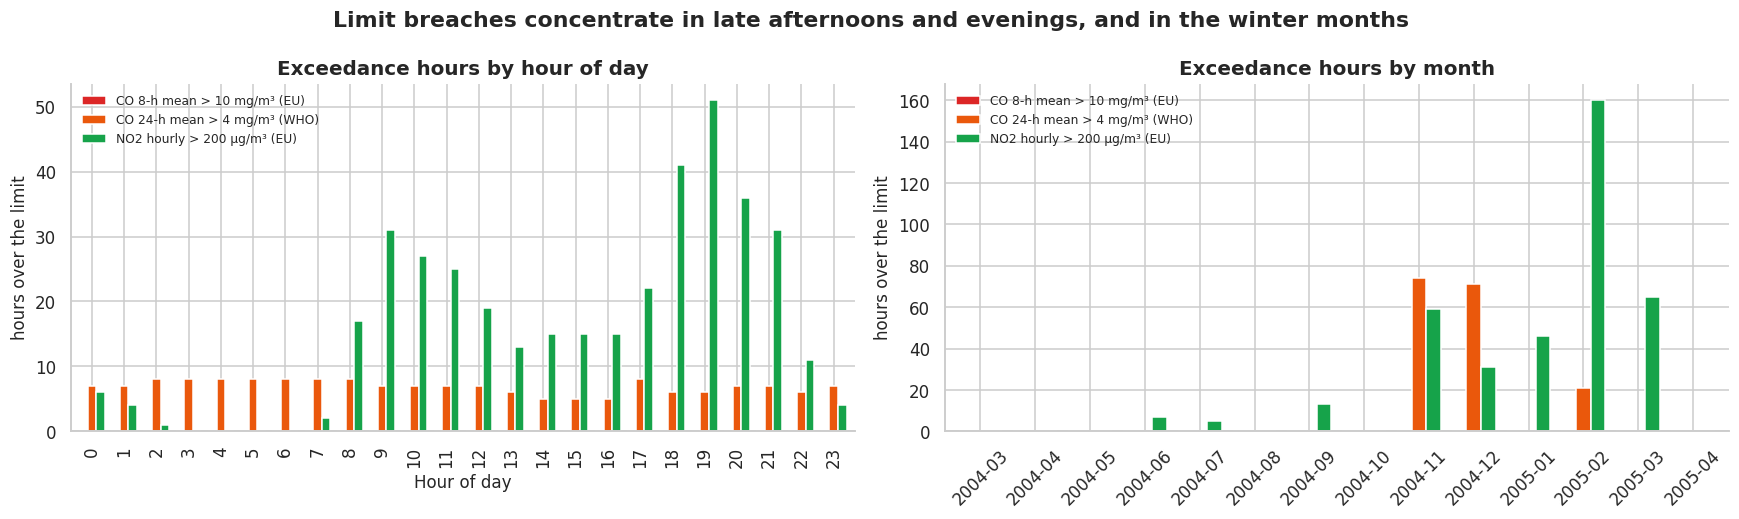

In [22]:
co8 = df[TARGET].rolling("8h", min_periods=6).mean()
co24 = df[TARGET].rolling("24h", min_periods=18).mean()
exceed = pd.DataFrame({
    "CO 8-h mean > 10 mg/m³ (EU)": co8 > 10,
    "CO 24-h mean > 4 mg/m³ (WHO)": co24 > 4,
    "NO2 hourly > 200 µg/m³ (EU)": df["NO2(GT)"] > 200,
})
summary = pd.DataFrame({
    "hours_exceeding": exceed.sum(),
    "days_with_any_exceedance": exceed.resample("D").sum().gt(0).sum(),
    "share_of_observed_hours_%": (exceed.sum() / df[TARGET].notna().sum() * 100).round(1),
})
display(summary)
benzene_annual = df["C6H6(GT)"].mean()
print(f"Benzene annual mean = {benzene_annual:.2f} µg/m³ vs EU annual limit 5 µg/m³  →  {'EXCEEDED' if benzene_annual > 5 else 'within limit'}")

ex_hour = exceed.groupby(exceed.index.hour).sum()
ex_month = exceed.groupby(exceed.index.strftime("%Y-%m")).sum()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ex_hour.plot(kind="bar", ax=axes[0], color=[COLORS["red"], COLORS["NOx(GT)"], COLORS["NO2(GT)"]], width=0.8)
axes[0].set_title("Exceedance hours by hour of day"); axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("hours over the limit")
ex_month.plot(kind="bar", ax=axes[1], color=[COLORS["red"], COLORS["NOx(GT)"], COLORS["NO2(GT)"]], width=0.8)
axes[1].set_title("Exceedance hours by month"); axes[1].set_xlabel(""); axes[1].set_ylabel("hours over the limit")
for ax in axes: ax.legend(fontsize=8)
plt.setp(axes[1].get_xticklabels(), rotation=45)
fig.suptitle("Limit breaches concentrate in late afternoons and evenings, and in the winter months", fontweight="bold")
plt.tight_layout(); savefig("exceedances"); plt.show()

**What the exceedances tell us.** The EU 8-hour CO limit of 10 mg/m³ was never breached: the highest 8-hour mean in the whole year stays below it. The stricter WHO 24-hour guideline of 4 mg/m³ was exceeded for 166 hours spread over 15 days in November and December 2004 and February 2005. NO2 is the bigger problem: the EU hourly limit of 200 µg/m³ was broken in 386 hours on 87 different days (5% of all observed hours), with February 2005 alone contributing 160 of those hours, and the breaches cluster between 09:00 and 11:00 and between 18:00 and 21:00. Benzene also exceeds the EU annual limit of 5 µg/m³, with an annual mean of about 10 µg/m³. So the site complies with the CO law on paper while failing the WHO health guideline and the NO2 and benzene limits, and nearly every breach lands in winter rush hours.

## 5. Feature engineering

The brief asks us to predict CO from the environmental and temporal factors a city could actually
use. We build two feature sets and compare them, because the comparison is itself a decision-relevant
result:

* **Set A — urban factors only (the headline model):** hour of day, day of week, weekend, public
  holiday and rush-hour flags, season, and weather (T, RH, AH). These are known in advance for any
  hour, so a model on Set A can answer *"in which situations will pollution be high?"* This is the
  model the policy section is built on.
* **Set B — Set A plus the five cheap sensor readings (a sensor-calibration comparison).** This tells
  us how much a low-cost sensor adds over time-and-weather alone, which is the question a city asks
  before buying sensors. It will score higher, but it can only be used where a sensor is installed.

What we deliberately leave out, and why:

| Excluded | Reason |
|---|---|
| Other reference pollutants (`NOx(GT)`, `NO2(GT)`, `C6H6(GT)`) | A city without a CO analyser would not have those analysers either; using them would be circular. |
| Lagged values of CO | That turns the task into time-series forecasting, which the brief says is not required, and it would hide the effect of the urban factors we want to measure. |
| `NMHC(GT)` | Dropped in Section 2 (90% missing). |

**Encoding choices.** Hour of day has *two* peaks (morning and evening rush hour), so a single
sine/cosine wave cannot represent it. For the linear models we therefore one-hot encode hour, weekday
and season; tree models receive hour and weekday as plain integers because trees split on thresholds
and handle that naturally.

In [23]:
def add_time_features(d):
    d = d.copy()
    d["hour"] = d.index.hour
    d["dow"] = d.index.dayofweek                       # Monday = 0
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    d["is_rush"] = d["hour"].isin([7, 8, 9, 17, 18, 19, 20]).astype(int)   # standard commuting windows, fixed a priori
    d["month"] = d.index.month
    # Italian public holidays inside the data period: traffic on these weekdays behaves like a weekend
    holidays = pd.to_datetime(["2004-04-12", "2004-04-25", "2004-05-01", "2004-06-02", "2004-08-15", "2004-11-01",
                               "2004-12-08", "2004-12-25", "2004-12-26", "2005-01-01", "2005-01-06", "2005-03-28"])
    d["is_holiday"] = d.index.normalize().isin(holidays).astype(int)
    d["season"] = d["month"].map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                                  6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"})
    return d

feat = add_time_features(df)

CAT_FEATURES = ["hour", "dow", "season"]
NUM_FEATURES = ["is_weekend", "is_rush", "is_holiday"] + WEATHER
FEATURES_A = CAT_FEATURES + NUM_FEATURES
FEATURES_B = FEATURES_A + SENSORS
feat[FEATURES_B + [TARGET]].head()

,hour,dow,season,is_weekend,is_rush,is_holiday,T,RH,AH,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),CO(GT)
datetime,,,,,,,,,,,,,,,
2004-03-10 18:00:00,18,2,spring,0,1,0,13.6,48.9,0.7578,1360.0,1046.0,1056.0,1692.0,1268.0,2.6
2004-03-10 19:00:00,19,2,spring,0,1,0,13.3,47.7,0.7255,1292.0,955.0,1174.0,1559.0,972.0,2.0
2004-03-10 20:00:00,20,2,spring,0,1,0,11.9,54.0,0.7502,1402.0,939.0,1140.0,1555.0,1074.0,2.2
2004-03-10 21:00:00,21,2,spring,0,0,0,11.0,60.0,0.7867,1376.0,948.0,1092.0,1584.0,1203.0,2.2
2004-03-10 22:00:00,22,2,spring,0,0,0,11.2,59.6,0.7888,1272.0,836.0,1205.0,1490.0,1110.0,1.6


### 5.1 Multicollinearity check (an assumption of linear regression)

Absolute humidity is computed from temperature and relative humidity, so the three weather variables may
carry overlapping information. We check with the Variance Inflation Factor (VIF); values above 10 are
the usual warning sign for a linear model.

In [24]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = feat[WEATHER].dropna()
X_vif = (X_vif - X_vif.mean()) / X_vif.std()
X_vif.insert(0, "const", 1.0)
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]}, index=WEATHER).round(2)
X_vif2 = X_vif.drop(columns=["AH"])
vif["VIF_without_AH"] = pd.Series([variance_inflation_factor(X_vif2.values, i) for i in range(1, X_vif2.shape[1])], index=["T", "RH"]).round(2)
vif

,VIF,VIF_without_AH
T,12.39,1.5
RH,7.25,1.5
AH,8.47,NaN


**What the VIF tells us.** Temperature has a VIF of 12.4, above the usual threshold of 10, and absolute humidity is at 8.5. That is expected: absolute humidity is calculated from temperature and relative humidity, so the three variables partly repeat each other. For the linear models we therefore drop absolute humidity, which brings the remaining VIFs well under 10 (second column). The tree models keep all three because they are not affected by multicollinearity in the same way, and absolute humidity carries a little extra information for them.

## 6. Modelling

### 6.1 A split that respects time

Consecutive hours of pollution are near-duplicates of each other (temporal autocorrelation). If we
shuffled the hours and split them at random, the test set would be full of hours whose neighbours are
in the training set, and the scores would be optimistically biased. So we split **chronologically**: the first 80% of the
timeline (March 2004 to mid-January 2005) is for training, the last 20% (mid-January to April 2005) is
held out for testing. Every season still appears in the training period.

For hyperparameter tuning we use `TimeSeriesSplit` cross-validation inside the training period, for the
same reason. We also run one random split at the end of the section purely to show how much it inflates
the score.

In [25]:
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model_df = feat.dropna(subset=[TARGET] + FEATURES_B).copy()
cut = int(len(model_df) * 0.8)
train, test = model_df.iloc[:cut], model_df.iloc[cut:]
y_train, y_test = train[TARGET], test[TARGET]
print(f"Rows usable for modelling: {len(model_df):,}  (rows dropped because CO or an input was missing: {len(feat) - len(model_df):,})")
print(f"Train: {len(train):,} hours, {train.index.min():%d %b %Y} → {train.index.max():%d %b %Y}")
print(f"Test : {len(test):,} hours, {test.index.min():%d %b %Y} → {test.index.max():%d %b %Y}")

Rows usable for modelling: 7,358  (rows dropped because CO or an input was missing: 1,999)
Train: 5,886 hours, 10 Mar 2004 → 28 Jan 2005
Test : 1,472 hours, 28 Jan 2005 → 04 Apr 2005


### 6.2 Preprocessing pipelines

Everything that learns from the data (the scaler, the one-hot encoder, the model) lives inside one
scikit-learn `Pipeline`, fitted on the training rows only. That is what stops information from the test
set leaking into training, and it is also what lets us save the whole thing as a single model file.

In [26]:
def make_preprocessor(kind, features):
    cats = [c for c in CAT_FEATURES if c in features]
    nums = [c for c in features if c not in CAT_FEATURES]
    if kind == "linear":
        # is_weekend and is_rush are exact combinations of the hour/weekday dummies, so they are
        # left out of the linear design matrix to avoid perfect multicollinearity (dummy-variable trap).
        # AH is computed from T and RH (VIF check in 5.1), so the linear models use T and RH only.
        nums = [c for c in nums if c not in ("is_weekend", "is_rush", "AH")]
        return ColumnTransformer([
            ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"), cats),
            ("scale", StandardScaler(), nums)], verbose_feature_names_out=False)
    # tree models: season → ordinal code, everything else passes through untouched
    return ColumnTransformer([
        ("season", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), ["season"])],
        remainder="passthrough", verbose_feature_names_out=False)

def make_pipeline(name, features):
    estimators = {
        "Linear Regression": ("linear", LinearRegression()),
        "Ridge Regression":  ("linear", RidgeCV(alphas=np.logspace(-2, 3, 30), cv=TimeSeriesSplit(5))),
        "Random Forest":     ("tree", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                            random_state=RANDOM_STATE, n_jobs=-1)),
        "Gradient Boosting": ("tree", HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05,
                                                                    random_state=RANDOM_STATE)),
    }
    kind, est = estimators[name]
    return Pipeline([("prep", make_preprocessor(kind, features)), ("model", est)])

def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    n = len(y)
    k = len(pipe.named_steps["prep"].get_feature_names_out())   # columns the model actually sees, after encoding
    r2 = r2_score(y, pred)
    return {"RMSE": np.sqrt(mean_squared_error(y, pred)), "MAE": mean_absolute_error(y, pred),
            "R2": r2, "Adj_R2": 1 - (1 - r2) * (n - 1) / (n - k - 1)}

def cv_rmse(pipe, X, y):
    # Five time-ordered folds inside the training period: each fold trains on the past and scores on the next block
    scores = cross_val_score(pipe, X, y, cv=TimeSeriesSplit(n_splits=5), scoring="neg_root_mean_squared_error", n_jobs=-1)
    return -scores.mean(), scores.std()

### 6.3 Train every model on both feature sets

The two **required** models are Linear Regression (the course's baseline, high bias / low variance) and
Random Forest (an ensemble of decision trees, low bias / higher variance). Ridge Regression and Gradient
Boosting are added as extra comparisons.

In [27]:
MODEL_NAMES = ["Linear Regression", "Ridge Regression", "Random Forest", "Gradient Boosting"]
FEATURE_SETS = {"A: urban factors": FEATURES_A, "B: + cheap sensors": FEATURES_B}

# Two naive baselines so the model scores have a reference point
baseline_mean = np.full(len(test), y_train.mean())
hour_means_train = y_train.groupby(train["hour"]).mean()
baseline_hour = test["hour"].map(hour_means_train).values
def metrics_from_pred(pred, y):
    return {"RMSE": np.sqrt(mean_squared_error(y, pred)), "R2": r2_score(y, pred), "MAE": mean_absolute_error(y, pred)}
b1, b2 = metrics_from_pred(baseline_mean, y_test), metrics_from_pred(baseline_hour, y_test)
results = [
    {"model": "Baseline: training mean", "features": "none", "CV_RMSE": np.nan, "CV_RMSE_std": np.nan, "train_RMSE": np.nan,
     "test_RMSE": b1["RMSE"], "train_R2": np.nan, "test_R2": b1["R2"], "test_Adj_R2": np.nan, "test_MAE": b1["MAE"]},
    {"model": "Baseline: hour-of-day mean", "features": "hour only", "CV_RMSE": np.nan, "CV_RMSE_std": np.nan, "train_RMSE": np.nan,
     "test_RMSE": b2["RMSE"], "train_R2": np.nan, "test_R2": b2["R2"], "test_Adj_R2": np.nan, "test_MAE": b2["MAE"]},
]
fitted = {}
for set_name, feats in FEATURE_SETS.items():
    for name in MODEL_NAMES:
        pipe = make_pipeline(name, feats)
        cv_m, cv_s = cv_rmse(pipe, train[feats], y_train)
        pipe.fit(train[feats], y_train)
        tr, te = evaluate(pipe, train[feats], y_train), evaluate(pipe, test[feats], y_test)
        fitted[(name, set_name)] = pipe
        results.append({"model": name, "features": set_name, "CV_RMSE": cv_m, "CV_RMSE_std": cv_s,
                        "train_RMSE": tr["RMSE"], "test_RMSE": te["RMSE"],
                        "train_R2": tr["R2"], "test_R2": te["R2"], "test_Adj_R2": te["Adj_R2"], "test_MAE": te["MAE"]})
results = pd.DataFrame(results).round(3)
results.sort_values("test_RMSE")

,model,features,CV_RMSE,CV_RMSE_std,train_RMSE,test_RMSE,train_R2,test_R2,test_Adj_R2,test_MAE
8,Random Forest,B: + cheap sensors,0.469,0.174,0.174,0.497,0.986,0.854,0.852,0.337
9,Gradient Boosting,B: + cheap sensors,0.471,0.173,0.175,0.506,0.986,0.849,0.847,0.352
7,Ridge Regression,B: + cheap sensors,0.519,0.166,0.448,0.577,0.907,0.803,0.797,0.453
6,Linear Regression,B: + cheap sensors,0.518,0.149,0.447,0.597,0.907,0.789,0.783,0.470
5,Gradient Boosting,A: urban factors,1.203,0.385,0.568,1.010,0.850,0.395,0.392,0.759
4,Random Forest,A: urban factors,1.171,0.322,0.428,1.031,0.915,0.370,0.366,0.775
2,Linear Regression,A: urban factors,1.204,0.243,1.072,1.040,0.466,0.359,0.344,0.817
3,Ridge Regression,A: urban factors,1.215,0.256,1.072,1.040,0.466,0.359,0.344,0.817
1,Baseline: hour-of-day mean,hour only,NaN,NaN,NaN,1.093,NaN,0.293,NaN,0.838
0,Baseline: training mean,none,NaN,NaN,NaN,1.319,NaN,-0.031,NaN,1.068


### 6.4 Tuning the Random Forest with time-aware cross-validation

A small grid over tree depth, leaf size and the number of features tried at each split, scored on RMSE
across five `TimeSeriesSplit` folds inside the training period.

In [28]:
param_grid = {"model__max_depth": [None, 12], "model__min_samples_leaf": [1, 4], "model__max_features": ["sqrt", 0.5]}
tscv = TimeSeriesSplit(n_splits=5)
rf_grid = GridSearchCV(make_pipeline("Random Forest", FEATURES_B).set_params(model__n_estimators=200),
                       param_grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(train[FEATURES_B], y_train)

print("Best parameters:", rf_grid.best_params_)
print(f"Best CV RMSE   : {-rf_grid.best_score_:.3f} mg/m³")
rf_tuned = rf_grid.best_estimator_
te = evaluate(rf_tuned, test[FEATURES_B], y_test); tr = evaluate(rf_tuned, train[FEATURES_B], y_train)
results = pd.concat([results, pd.DataFrame([{"model": "Random Forest (tuned)", "features": "B: + cheap sensors",
    "CV_RMSE": -rf_grid.best_score_, "CV_RMSE_std": rf_grid.cv_results_["std_test_score"][rf_grid.best_index_],
    "train_RMSE": tr["RMSE"], "test_RMSE": te["RMSE"], "train_R2": tr["R2"], "test_R2": te["R2"],
    "test_Adj_R2": te["Adj_R2"], "test_MAE": te["MAE"]}]).round(3)], ignore_index=True)
fitted[("Random Forest (tuned)", "B: + cheap sensors")] = rf_tuned

cv_table = pd.DataFrame(rf_grid.cv_results_)[["param_model__max_depth", "param_model__min_samples_leaf", "param_model__max_features", "mean_test_score", "std_test_score"]]
cv_table["mean_CV_RMSE"] = -cv_table.pop("mean_test_score"); cv_table = cv_table.rename(columns={"std_test_score": "std_CV_RMSE"})
cv_table.sort_values("mean_CV_RMSE").round(3)

Best parameters: {'model__max_depth': 12, 'model__max_features': 0.5, 'model__min_samples_leaf': 1}
Best CV RMSE   : 0.472 mg/m³


,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,std_CV_RMSE,mean_CV_RMSE
6,12,1,0.5,0.180,0.472
2,None,1,0.5,0.178,0.474
3,None,4,0.5,0.172,0.477
7,12,4,0.5,0.172,0.478
0,None,1,sqrt,0.174,0.495
4,12,1,sqrt,0.175,0.497
1,None,4,sqrt,0.171,0.505
5,12,4,sqrt,0.173,0.508


### 6.5 Why we did not use a random split

Same model, same features, but the hours are shuffled before splitting:

In [29]:
Xa, ya = model_df[FEATURES_A], model_df[TARGET]
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(Xa, ya, test_size=0.2, random_state=RANDOM_STATE, shuffle=True)
rf_random = make_pipeline("Random Forest", FEATURES_A).fit(Xtr_r, ytr_r)
r2_random = r2_score(yte_r, rf_random.predict(Xte_r))
r2_chrono = results.loc[(results.model == "Random Forest") & (results.features == "A: urban factors"), "test_R2"].iloc[0]
print(f"Random Forest, feature set A")
print(f"  random (shuffled) split  test R² = {r2_random:.3f}")
print(f"  chronological split      test R² = {r2_chrono:.3f}")
print(f"  → the shuffled split overstates performance by {r2_random - r2_chrono:+.3f} R² because neighbouring, near-identical hours land on both sides of the split.")

Random Forest, feature set A
  random (shuffled) split  test R² = 0.616
  chronological split      test R² = 0.370
  → the shuffled split overstates performance by +0.246 R² because neighbouring, near-identical hours land on both sides of the split.


## 7. Evaluation

Metrics on the held-out last 20% of the year. **RMSE** is in the units of CO (mg/m³) and punishes big
misses, which matters for pollution alerts. **R²** is the share of hour-to-hour variation the model
explains. Adjusted R² corrects for the number of inputs, and MAE is the typical absolute miss.

In [30]:
results_sorted = results.sort_values("test_RMSE").reset_index(drop=True)
display(results_sorted.style.format({c: "{:.3f}" for c in results_sorted.columns[2:]}, na_rep="–")
        .background_gradient(subset=["test_RMSE"], cmap="RdYlGn_r").background_gradient(subset=["test_R2"], cmap="RdYlGn"))

best_row = results_sorted.iloc[0]
best_A_row = results[results.features == "A: urban factors"].sort_values("test_RMSE").iloc[0]
print(f"Best urban-factors model (set A): {best_A_row.model}  test RMSE = {best_A_row.test_RMSE:.3f}, test R² = {best_A_row.test_R2:.3f}")
BEST_NAME, BEST_SET = best_row["model"], best_row["features"]
best_pipe = fitted[(BEST_NAME, BEST_SET)]
BEST_FEATURES = FEATURE_SETS[BEST_SET]
print(f"\nBest model on the held-out period: {BEST_NAME} with feature set {BEST_SET}")
print(f"  test RMSE = {best_row.test_RMSE:.3f} mg/m³   test R² = {best_row.test_R2:.3f}   test MAE = {best_row.test_MAE:.3f} mg/m³")

,model,features,CV_RMSE,CV_RMSE_std,train_RMSE,test_RMSE,train_R2,test_R2,test_Adj_R2,test_MAE
0,Random Forest (tuned),B: + cheap sensors,0.472,0.180,0.176,0.490,0.986,0.858,0.856,0.334
1,Random Forest,B: + cheap sensors,0.469,0.174,0.174,0.497,0.986,0.854,0.852,0.337
2,Gradient Boosting,B: + cheap sensors,0.471,0.173,0.175,0.506,0.986,0.849,0.847,0.352
3,Ridge Regression,B: + cheap sensors,0.519,0.166,0.448,0.577,0.907,0.803,0.797,0.453
4,Linear Regression,B: + cheap sensors,0.518,0.149,0.447,0.597,0.907,0.789,0.783,0.470
5,Gradient Boosting,A: urban factors,1.203,0.385,0.568,1.010,0.850,0.395,0.392,0.759
6,Random Forest,A: urban factors,1.171,0.322,0.428,1.031,0.915,0.370,0.366,0.775
7,Linear Regression,A: urban factors,1.204,0.243,1.072,1.040,0.466,0.359,0.344,0.817
8,Ridge Regression,A: urban factors,1.215,0.256,1.072,1.040,0.466,0.359,0.344,0.817
9,Baseline: hour-of-day mean,hour only,–,–,–,1.093,–,0.293,–,0.838


Best urban-factors model (set A): Gradient Boosting  test RMSE = 1.010, test R² = 0.395

Best model on the held-out period: Random Forest (tuned) with feature set B: + cheap sensors
  test RMSE = 0.490 mg/m³   test R² = 0.858   test MAE = 0.334 mg/m³


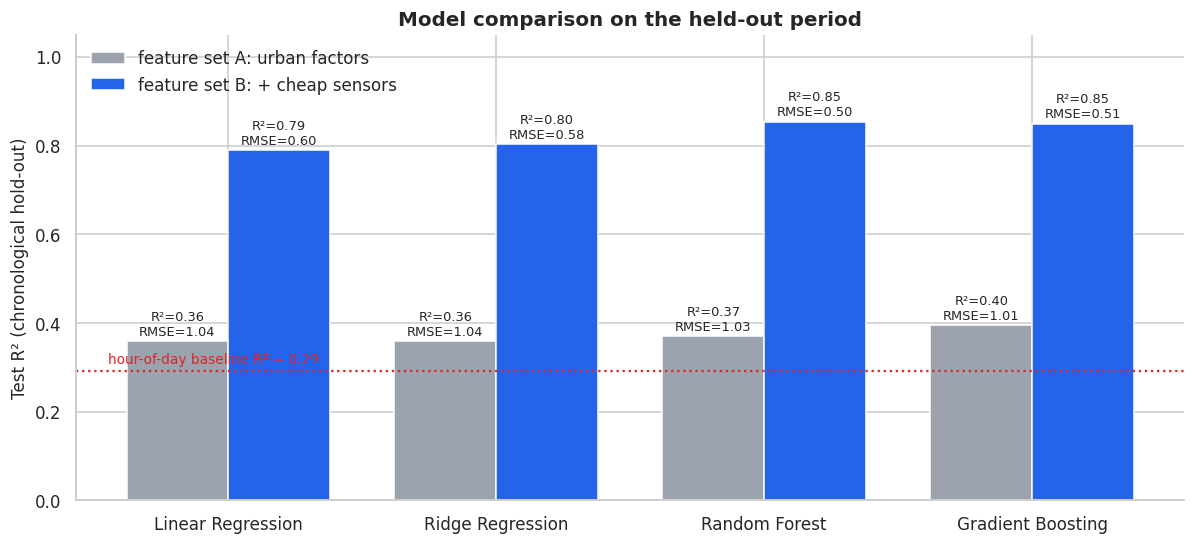

In [31]:
fig, ax = plt.subplots(figsize=(13, 5.5))
plot_df = results[results.model != "Random Forest (tuned)"]
x = np.arange(len(MODEL_NAMES)); w = 0.38
for i, (set_name, color) in enumerate(zip(FEATURE_SETS, [COLORS["grey"], COLORS["CO(GT)"]])):
    sub = plot_df[plot_df.features == set_name].set_index("model").loc[MODEL_NAMES]
    bars = ax.bar(x + (i - 0.5) * w, sub["test_R2"], w, color=color, label=f"feature set {set_name}")
    ax.bar_label(bars, labels=[f"R²={r:.2f}\nRMSE={e:.2f}" for r, e in zip(sub["test_R2"], sub["test_RMSE"])], fontsize=8.5, padding=2)
ax.axhline(b2["R2"], ls=":", color=COLORS["red"]); ax.text(-0.45, b2["R2"] + 0.015, f"hour-of-day baseline R² = {b2['R2']:.2f}", color=COLORS["red"], fontsize=9, ha="left")
ax.set_xticks(x, MODEL_NAMES); ax.set_ylabel("Test R² (chronological hold-out)"); ax.set_ylim(0, 1.05)
ax.legend(loc="upper left"); ax.set_title("Model comparison on the held-out period")
savefig("model_comparison"); plt.show()

**What the comparison tells us.** Three results matter for the city.

1. **Time and weather alone explain only about a third of the hour-to-hour variation.** With feature set A every model lands between R² = 0.36 and 0.37 and an RMSE of about 1.03 mg/m³, and the hour-of-day baseline already reaches 0.29. The remaining two thirds are driven by things not in the data: actual traffic counts, wind, and the day-to-day meteorology that decides whether pollution disperses or builds up.
2. **Adding the five cheap sensors lifts R² to about 0.85 and halves the RMSE to 0.49 mg/m³.** The tuned Random Forest and Gradient Boosting are tied at the top, and even the linear model jumps to 0.79. This is the business case for low-cost sensors: a sensor box plus a model gets within half a milligram of a certified analyser.
3. **Linear and tree models tell a bias-variance story.** Linear Regression and Ridge have train and test scores close together (high bias, low variance). The Random Forest fits the training data almost perfectly (train R² 0.99) but drops to 0.86 on unseen months (lower bias, higher variance), and tuning (depth 12, half the features tried per split) only moved the test RMSE from 0.498 to 0.490. Gradient Boosting generalises equally well with a smaller gap. Because feature set B is only usable where a sensor exists, the policy section uses the Set A forest for scenario planning and reports the Set B model as what a sensor network could deliver.

The random-split check in 6.5 shows why the chronological split matters: shuffling the hours would have reported R² = 0.62 instead of 0.37 for the same urban-factors forest, an overstatement of 0.25.

### 7.1 Diagnostics for the best model

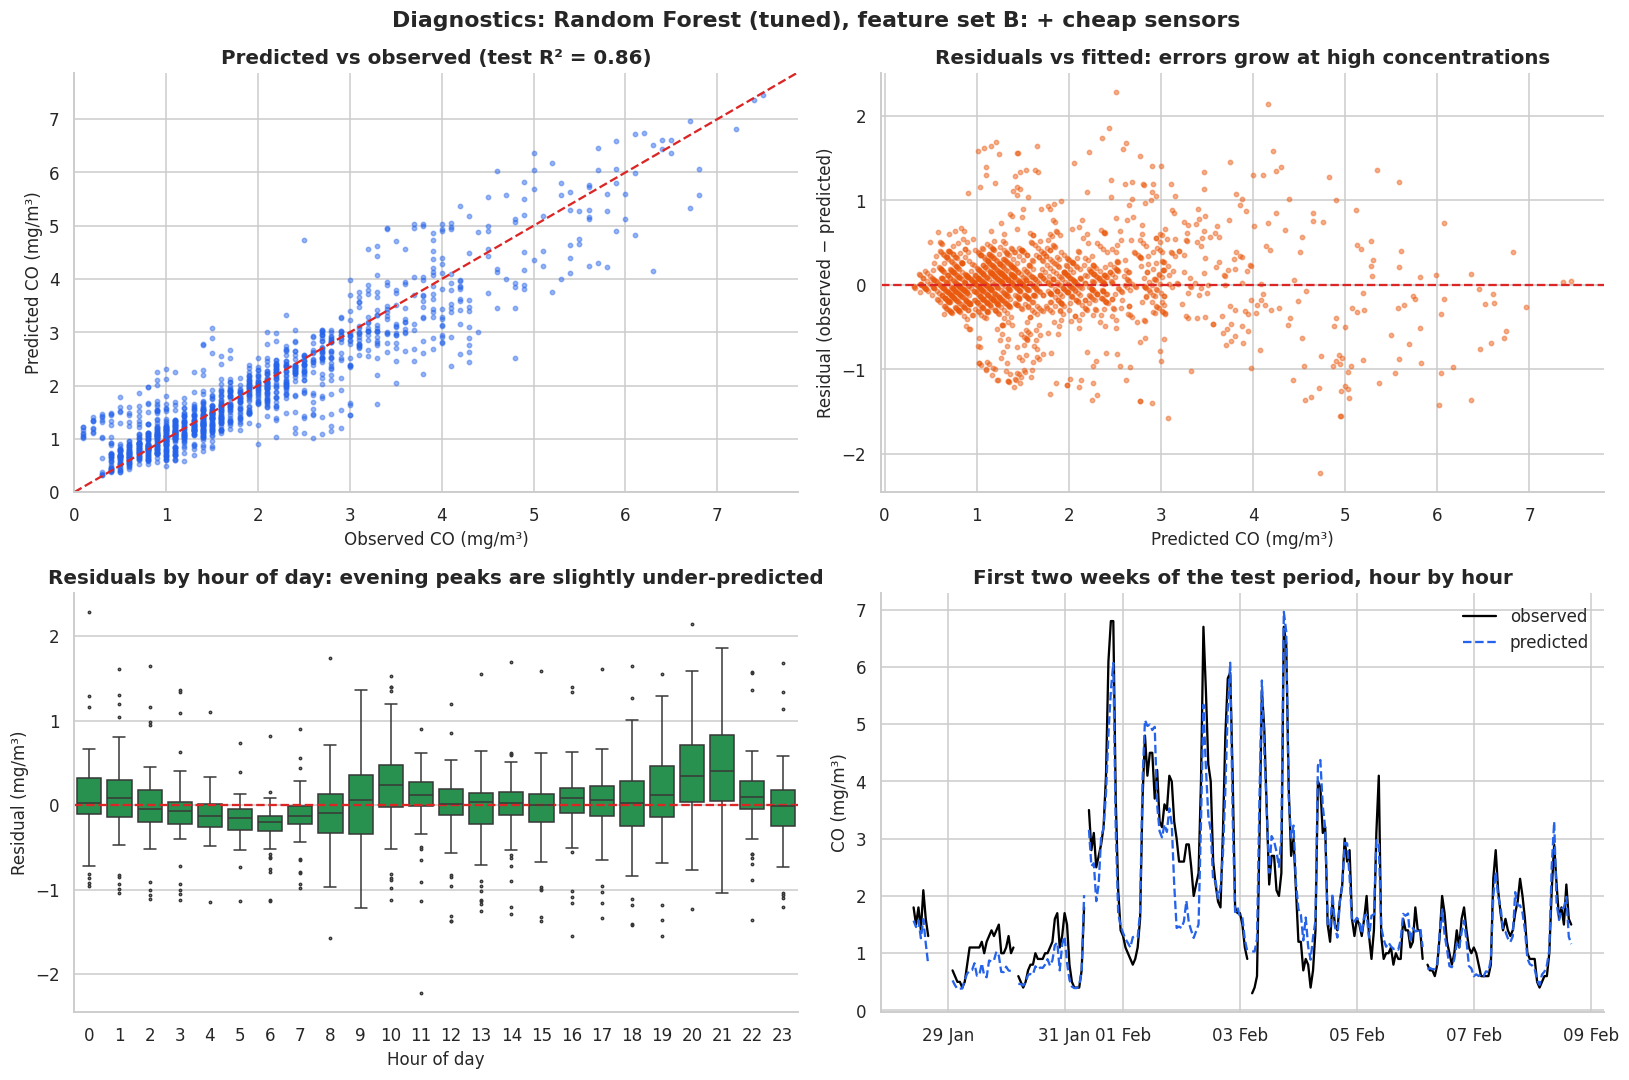

In [32]:
pred_test = pd.Series(best_pipe.predict(test[BEST_FEATURES]), index=test.index)
resid = y_test - pred_test

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax = axes[0, 0]
ax.scatter(y_test, pred_test, s=8, alpha=0.45, color=COLORS["CO(GT)"])
lim = [0, max(y_test.max(), pred_test.max()) * 1.05]
ax.plot(lim, lim, "--", color=COLORS["red"]); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Observed CO (mg/m³)"); ax.set_ylabel("Predicted CO (mg/m³)"); ax.set_title(f"Predicted vs observed (test R² = {best_row.test_R2:.2f})")

ax = axes[0, 1]
ax.scatter(pred_test, resid, s=8, alpha=0.45, color=COLORS["NOx(GT)"]); ax.axhline(0, color=COLORS["red"], ls="--")
ax.set_xlabel("Predicted CO (mg/m³)"); ax.set_ylabel("Residual (observed − predicted)"); ax.set_title("Residuals vs fitted: errors grow at high concentrations")

ax = axes[1, 0]
sns.boxplot(x=resid.index.hour, y=resid.values, ax=ax, color=COLORS["NO2(GT)"], fliersize=1.5)
ax.axhline(0, color=COLORS["red"], ls="--"); ax.set_xlabel("Hour of day"); ax.set_ylabel("Residual (mg/m³)"); ax.set_title("Residuals by hour of day: evening peaks are slightly under-predicted")

ax = axes[1, 1]
window = pd.date_range(test.index[0], test.index[0] + pd.Timedelta(days=14), freq="h")   # gaps in the data break the line
ax.plot(window, y_test.reindex(window), color="black", lw=1.5, label="observed")
ax.plot(window, pred_test.reindex(window), color=COLORS["CO(GT)"], lw=1.5, ls="--", label="predicted")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend()
ax.set_ylabel("CO (mg/m³)"); ax.set_title("First two weeks of the test period, hour by hour")
fig.suptitle(f"Diagnostics: {BEST_NAME}, feature set {BEST_SET}", fontweight="bold")
plt.tight_layout(); savefig("best_model_diagnostics"); plt.show()

**What the diagnostics tell us.** The predicted-versus-observed cloud hugs the diagonal up to about 4 mg/m³ and fans out above it, so the model is most reliable at everyday levels and least reliable during the worst episodes. The residual plot shows the same thing: errors grow with the predicted level, and the biggest misses are under-predictions of peaks, which is the wrong direction for an alert system (a cautious city would lower its alert threshold to compensate). By hour of day the residuals are centred on zero except for 20:00 to 21:00, where the model under-predicts the evening peak by about 0.3 mg/m³ on average. The trace of the first days of the test period shows the model tracking the daily cycle closely, including the sharp peaks of 1 to 3 February and the quiet weekend of 5 to 6 February; the line stops on 9 February because the analyser was offline for the following days.

## 8. What drives pollution? Interpreting the models

A model is only useful to a city if we can say *which* factors matter and *in which situations* pollution
will be high. We look at this from three angles.

### 8.1 Linear model coefficients (feature set A)

Each coefficient is the change in CO (mg/m³) for a one-unit change in that input (one standard deviation
for the scaled weather variables), holding everything else constant. The reference categories are
hour 0, Monday and autumn.

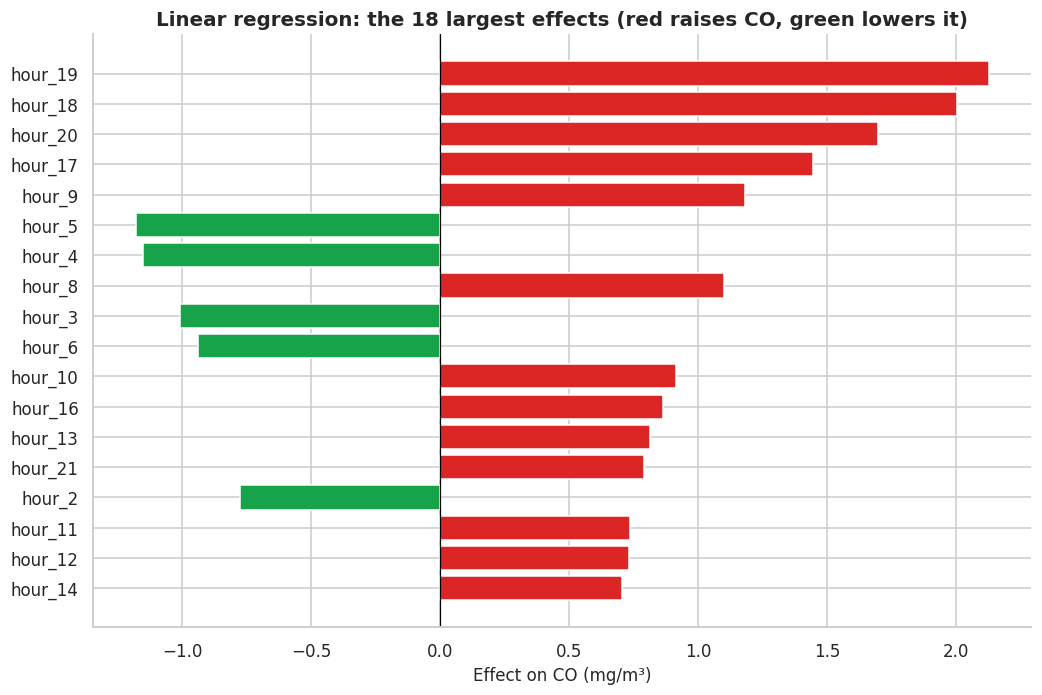

In [33]:
lin_A = fitted[("Linear Regression", "A: urban factors")]
coef = pd.Series(lin_A.named_steps["model"].coef_, index=lin_A.named_steps["prep"].get_feature_names_out())
coef_plot = coef.reindex(coef.abs().sort_values(ascending=False).index[:18])

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(coef_plot.index[::-1], coef_plot.values[::-1], color=[COLORS["red"] if v > 0 else COLORS["NO2(GT)"] for v in coef_plot.values[::-1]])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("Effect on CO (mg/m³)")
ax.set_title("Linear regression: the 18 largest effects (red raises CO, green lowers it)")
savefig("linear_coefficients"); plt.show()

### 8.2 Random Forest: which inputs the model relies on

Impurity-based importance says how much each feature was used to split the trees. **Permutation
importance** is the more honest measure: it shuffles one feature in the *test* set and records how much
the RMSE gets worse. We show both for the Set A forest (urban factors only) and for the best overall model.

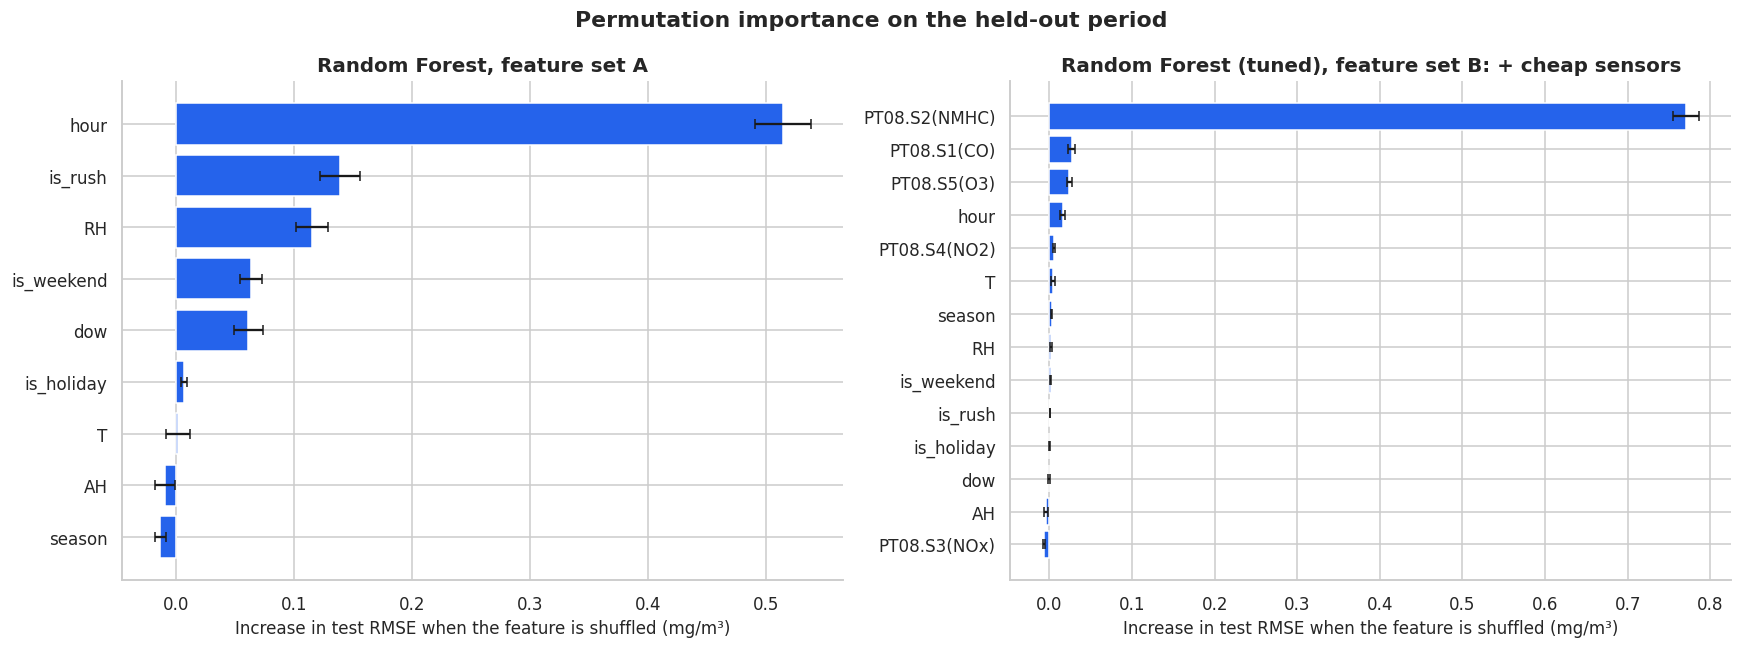

In [34]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

rf_A = fitted[("Random Forest", "A: urban factors")]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (pipe, feats, title) in zip(axes, [(rf_A, FEATURES_A, "Random Forest, feature set A"), (best_pipe, BEST_FEATURES, f"{BEST_NAME}, feature set {BEST_SET}")]):
    pi = permutation_importance(pipe, test[feats], y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error", n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=feats).sort_values()
    err = pd.Series(pi.importances_std, index=feats).loc[imp.index]
    ax.barh(imp.index, imp.values, xerr=err.values, color=COLORS["CO(GT)"], capsize=3)
    ax.set_xlabel("Increase in test RMSE when the feature is shuffled (mg/m³)"); ax.set_title(title)
fig.suptitle("Permutation importance on the held-out period", fontweight="bold")
plt.tight_layout(); savefig("permutation_importance"); plt.show()

**What the coefficients and importance plots tell us.** The linear coefficients are a numerical version of the hourly profile: relative to midnight, the hours 17:00 to 20:00 add 1.4 to 2.1 mg/m³ of CO, the morning hours 08:00 to 09:00 add about 1.1 mg/m³, and the hours 03:00 to 06:00 subtract about 1 mg/m³. For the urban-factors forest the hour of day dominates: shuffling it raises test RMSE by 0.5 mg/m³, three to four times more than the next feature. The rush-hour flag, relative humidity, the weekend flag and day of week follow, while temperature, absolute humidity, the holiday flag and season add nothing the model can use on unseen months (their bars sit at zero or slightly below, which is noise). Once the sensors are added, the picture flips: the S2 sensor (nominally for hydrocarbons, but responding to the whole traffic exhaust mix) carries almost all of the signal (shuffling it costs 0.75 mg/m³ of RMSE), the CO and ozone sensors add small corrections, and the time and weather features barely matter any more. The two charts together show that the sensors are not adding to the time-of-day signal, they are replacing it with a direct measurement of the exhaust mix.

### 8.3 Partial dependence: the shape of each effect

A partial dependence plot shows what the model predicts as one input changes while all the others are
held at their observed values. This is the *adjusted* view of the weather effects: unlike the raw
correlations in Section 4.4, hour of day and season are now held constant, so we see what temperature
and humidity do on their own. We use the Set A forest because it uses only the factors a planner can
reason about. (The hour effect is shown in the next subsection via the scenario grid, because the
rush-hour flag is derived from the hour and must change with it.)

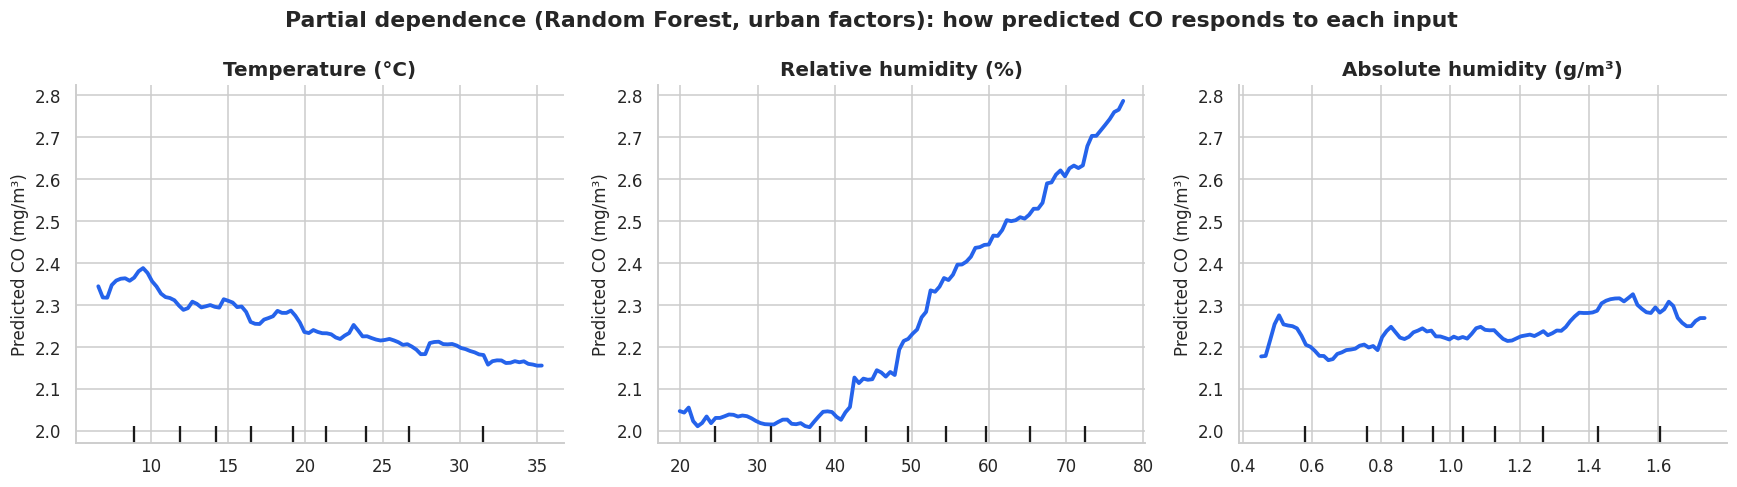

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
PartialDependenceDisplay.from_estimator(rf_A, train[FEATURES_A], features=["T", "RH", "AH"],
                                        kind="average", ax=axes, line_kw={"color": COLORS["CO(GT)"], "lw": 2.5})
titles = ["Temperature (°C)", "Relative humidity (%)", "Absolute humidity (g/m³)"]
for ax, t in zip(axes, titles):
    ax.set_title(t); ax.set_ylabel("Predicted CO (mg/m³)"); ax.set_xlabel("")
fig.suptitle("Partial dependence (Random Forest, urban factors): how predicted CO responds to each input", fontweight="bold")
plt.tight_layout(); savefig("partial_dependence"); plt.show()

**What the partial dependence tells us.** With hour, weekday and season held fixed, temperature has a small, steady negative effect: predicted CO falls by about 0.2 mg/m³ between 10 °C and 35 °C, consistent with warm air mixing pollutants upward. Relative humidity has the strongest adjusted effect of the three: predicted CO is flat up to about 40% and then climbs by 0.7 mg/m³ towards 80%, which is the signature of still, damp evenings when the air near the ground stops mixing. Absolute humidity is nearly flat. So the raw correlations in Section 4.4 were close to zero not because weather does nothing, but because its effects were hidden behind the time-of-day cycle. The honest version of the brief's rainfall question for this dataset is therefore: high humidity is associated with *more* CO, not less, once time is controlled for.

### 8.4 Decision tool: in which situations will CO be high?

We ask the Set A forest to predict CO for every combination of **hour × season** on a typical Tuesday,
with the weather set to that season's median. This is the kind of lookup table a traffic office could
use to time restrictions or alerts.

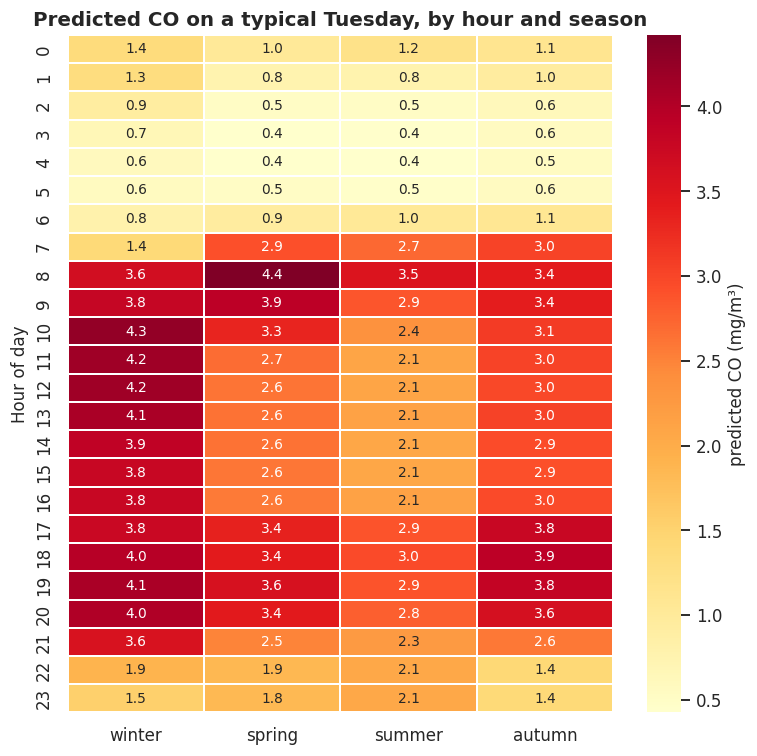

Eight highest-risk situations according to the model:


,season,hour,T,RH,predicted_CO
32,spring,8,16.9,47.2,4.42
10,winter,10,10.6,60.8,4.26
11,winter,11,10.6,60.8,4.16
12,winter,12,10.6,60.8,4.16
19,winter,19,10.6,60.8,4.08
13,winter,13,10.6,60.8,4.06
20,winter,20,10.6,60.8,4.03
18,winter,18,10.6,60.8,3.97


In [36]:
scenarios = []
season_weather = train.groupby("season")[WEATHER].median()
for season in ["winter", "spring", "summer", "autumn"]:
    for hour in range(24):
        scenarios.append({"hour": hour, "dow": 1, "season": season, "is_weekend": 0, "is_holiday": 0,
                          "is_rush": int(hour in [7, 8, 9, 17, 18, 19, 20]),
                          **season_weather.loc[season].to_dict()})
scenarios = pd.DataFrame(scenarios)
scenarios["predicted_CO"] = rf_A.predict(scenarios[FEATURES_A])
grid = scenarios.pivot(index="hour", columns="season", values="predicted_CO")[["winter", "spring", "summer", "autumn"]]

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(grid, cmap="YlOrRd", annot=True, fmt=".1f", annot_kws={"size": 9}, linewidths=0.3,
            cbar_kws={"label": "predicted CO (mg/m³)"}, ax=ax)
ax.set_title("Predicted CO on a typical Tuesday, by hour and season"); ax.set_ylabel("Hour of day"); ax.set_xlabel("")
savefig("scenario_grid"); plt.show()

worst = scenarios.nlargest(8, "predicted_CO")[["season", "hour", "T", "RH", "predicted_CO"]].round(2)
print("Eight highest-risk situations according to the model:"); display(worst)

In [37]:
# The same question answered directly from the observed data (no model), for cross-checking
obs = feat.dropna(subset=[TARGET]).copy()
obs["day"] = obs["dow"].map(dict(enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])))
top_obs = (obs.groupby(["season", "day", "hour"])[TARGET].agg(["mean", "count"])
              .query("count >= 15").sort_values("mean", ascending=False).head(10).round(2))
top_obs.columns = ["mean_observed_CO", "hours_observed"]
print("Ten worst (season, weekday, hour) combinations in the observed data:"); top_obs

Ten worst (season, weekday, hour) combinations in the observed data:


mean_observed_CO  hours_observed
season day hour                                  
spring Thu 19                5.01              15
           20                4.73              15
       Wed 9                 4.20              15
       Fri 19                4.09              17
       Tue 8                 3.99              15
       Fri 20                3.97              17
           9                 3.95              15
       Mon 19                3.95              15
       Thu 9                 3.82              15
           18                3.73              15

**What the scenario grid tells us.** Two different winter and spring problems appear. In winter the model predicts CO above 3.7 mg/m³ for every hour from 08:00 to 20:00 on a typical Tuesday, a thirteen-hour plateau, because cold, damp air keeps the morning emissions hanging around all day. In spring, summer and autumn the shape is two sharp spikes, with the single highest cell being spring at 08:00 (4.4 mg/m³) and the evening peak at 18:00 to 19:00; between the peaks the air clears to 2 to 3 mg/m³. Night hours are clean in every season (below 1 mg/m³ from 02:00 to 05:00). The observed top-ten table agrees: every entry is a weekday rush hour, led by spring Thursday evenings at 5.0 mg/m³. For a traffic office this suggests two different policies, a short rush-hour restriction for most of the year and an all-day measure in winter.

## 9. Export the trained model and demonstrate it

The full pipeline (preprocessing + model) is saved with `joblib`, so anyone can load one file and
predict from raw inputs. A small *model card* records what the model expects and how well it did.
We save two files:

* `models/co_best_model.joblib` — the best-scoring model (uses the cheap sensor readings).
* `models/co_urban_factors_model.joblib` — the Set A forest, for scenario planning when no sensor exists.

In [38]:
import joblib
joblib.dump(best_pipe, "models/co_best_model.joblib", compress=3)
joblib.dump(rf_A, "models/co_urban_factors_model.joblib", compress=3)

model_card = {
    "best_model": {"name": BEST_NAME, "feature_set": BEST_SET, "features": BEST_FEATURES,
                   "test_RMSE_mg_m3": round(float(best_row.test_RMSE), 3), "test_R2": round(float(best_row.test_R2), 3),
                   "test_MAE_mg_m3": round(float(best_row.test_MAE), 3)},
    "urban_factors_model": {"name": "Random Forest", "feature_set": "A: urban factors", "features": FEATURES_A,
                            "test_RMSE_mg_m3": float(results.loc[(results.model == "Random Forest") & (results.features == "A: urban factors"), "test_RMSE"].iloc[0]),
                            "test_R2": float(r2_chrono)},
    "target": TARGET, "target_units": "mg/m3",
    "train_period": [str(train.index.min()), str(train.index.max())],
    "test_period": [str(test.index.min()), str(test.index.max())],
    "data_source": "UCI ML Repository, Air Quality (ID 360), DOI 10.24432/C59K5F, CC BY 4.0",
    "random_state": RANDOM_STATE,
}
with open("models/model_card.json", "w") as f:
    json.dump(model_card, f, indent=2)
print(json.dumps(model_card, indent=2))
for fname in ["co_best_model.joblib", "co_urban_factors_model.joblib"]:
    size_mb = os.path.getsize(f"models/{fname}") / 1e6
    print(f"{fname}: {size_mb:.1f} MB")
    assert size_mb < 50, "keep model files small enough for GitHub"
print("\nFiles in models/:", os.listdir("models"))

{
  "best_model": {
    "name": "Random Forest (tuned)",
    "feature_set": "B: + cheap sensors",
    "features": [
      "hour",
      "dow",
      "season",
      "is_weekend",
      "is_rush",
      "is_holiday",
      "T",
      "RH",
      "AH",
      "PT08.S1(CO)",
      "PT08.S2(NMHC)",
      "PT08.S3(NOx)",
      "PT08.S4(NO2)",
      "PT08.S5(O3)"
    ],
    "test_RMSE_mg_m3": 0.49,
    "test_R2": 0.858,
    "test_MAE_mg_m3": 0.334
  },
  "urban_factors_model": {
    "name": "Random Forest",
    "feature_set": "A: urban factors",
    "features": [
      "hour",
      "dow",
      "season",
      "is_weekend",
      "is_rush",
      "is_holiday",
      "T",
      "RH",
      "AH"
    ],
    "test_RMSE_mg_m3": 1.031,
    "test_R2": 0.37
  },
  "target": "CO(GT)",
  "target_units": "mg/m3",
  "train_period": [
    "2004-03-10 18:00:00",
    "2005-01-28 09:00:00"
  ],
  "test_period": [
    "2005-01-28 10:00:00",
    "2005-04-04 14:00:00"
  ],
  "data_source": "UCI ML Repository, 

### 9.1 Demo: load the saved model and predict a real test hour

This is the cell we walk through in the demo video. We load the model file from disk (nothing from the
notebook's memory is reused), pick one hour from the held-out period, and compare the prediction with
what the analyser actually measured. Then we change only the hour of day to show the model responding.

In [39]:
loaded = joblib.load("models/co_best_model.joblib")
card = json.load(open("models/model_card.json"))

sample_time = test.index[test.index.hour == 18][5]           # an evening hour in the test period
sample = test.loc[[sample_time], card["best_model"]["features"]]
print(f"Test hour: {sample_time:%A %d %B %Y, %H:%M}")
display(sample.T.rename(columns={sample_time: "input value"}))

prediction = loaded.predict(sample)[0]
print(f"Model prediction : {prediction:.2f} mg/m³ CO")
print(f"Analyser measured: {y_test.loc[sample_time]:.2f} mg/m³ CO")

# What if the same conditions occurred at 3 am? (urban-factors model, no sensor needed)
planner = joblib.load("models/co_urban_factors_model.joblib")
what_if = test.loc[[sample_time], FEATURES_A].copy()
for h in [18, 3]:
    what_if["hour"] = h; what_if["is_rush"] = int(h in [7, 8, 9, 17, 18, 19, 20])
    print(f"Urban-factors model, same weather, hour = {h:02d}:00 → predicted CO {planner.predict(what_if)[0]:.2f} mg/m³")

Test hour: Thursday 03 February 2005, 18:00


datetime,input value
hour,18
dow,3
season,winter
is_weekend,0
is_rush,1
is_holiday,0
T,12.2
RH,44.8
AH,0.6342
PT08.S1(CO),1713.0


Model prediction : 6.96 mg/m³ CO
Analyser measured: 6.70 mg/m³ CO
Urban-factors model, same weather, hour = 18:00 → predicted CO 3.19 mg/m³
Urban-factors model, same weather, hour = 03:00 → predicted CO 0.60 mg/m³


## 10. Policy-oriented conclusion

### 10.1 What the city should do with this

The question we set out to answer was which urban and environmental factors are associated with high CO, and in which situations a city should expect pollution to be elevated. The evidence points to one decision above all others.

**1. Target weekday rush hours, not whole days.** The hour of day is the single strongest predictor in every model, and the harm is concentrated: 19:00 averages 3.7 mg/m³ against 0.7 mg/m³ at 05:00, weekday mornings at 08:00 are 60% dirtier than weekend mornings, and every NO2 limit breach clusters between 09:00 and 11:00 and 18:00 and 21:00. A traffic restriction, congestion charge or low-emission-zone rule that applies only in those windows would address most of the exceedance hours at a fraction of the cost of an all-day measure. The scenario grid in Section 8.4 gives the exact hours per season.

**2. Treat winter differently.** From November to February the model predicts elevated CO for the whole working day, not just the peaks, and all 15 WHO guideline breaches and most NO2 breaches fall in those months. Winter is when an all-day measure (for example alternate-plate days or heating-related restrictions) is justified. Humidity above about 50% is the weather signal to watch: it marks the still, damp conditions in which pollution builds up.

**3. Low-cost sensors are worth deploying, with a model and regular recalibration.** Time and weather explain about a third of the variation (R² 0.37); adding five cheap sensors raises that to 0.86 and halves the error to 0.49 mg/m³. A network of such boxes could give neighbourhood-level alerts that a single reference station cannot. But Section 4.5 showed a sensor calibrated in spring under-reading by 0.6 mg/m³ by December, so the deployment has to include a reference station and a recalibration schedule, otherwise the network would systematically under-report winter pollution.

**4. The compliance story is misleading.** The site never breaks the EU 8-hour CO limit, yet it exceeds the WHO 24-hour CO guideline on 15 days, the EU hourly NO2 limit on 87 days and the EU annual benzene limit. A city that reports only the CO legal limit would call this site clean. We would recommend reporting against the WHO guideline and the NO2 hourly limit, which is where the public-health risk actually shows up.

**What we would tell the traffic office in one sentence:** restrict traffic from 07:00 to 10:00 and 17:00 to 21:00 on weekdays all year, extend it to the whole working day in winter, and put cheap sensors on the busiest corridors with a plan to recalibrate them every season.

### 10.2 What this analysis does not capture

* **One site, one year.** Every number here describes a single roadside monitor in one Italian city from March 2004 to April 2005. The hourly and weekly shapes will transfer to other traffic-dominated sites; the exact levels will not, and a single year cannot separate a normal winter from an unusual one.
* **No particulate matter, no rainfall, no wind.** The brief asks whether rainfall suppresses particulate matter. This dataset has neither variable, so we answered the nearest available question (humidity and CO) and found the opposite sign. Wind speed and direction are probably the biggest missing explanatory variables: they decide whether emissions disperse, and their absence is the most likely reason two thirds of the hour-to-hour variation stays unexplained by time and weather.
* **No traffic counts.** We infer that traffic is the source from the rush-hour shape and the weekday-weekend gap, but we never observe it. A traffic counter at the site would turn that inference into a measurement and would almost certainly be the single most valuable extra column.
* **Sensor data is a proxy.** The cheap sensors drift (Section 4.5), the reference analysers were offline for 18% of the hours, and the outages cluster in particular months, so the monthly comparisons are uneven in quality. We never filled in the target variable, which keeps the models honest but means the long outages are simply absent.
* **Association, not causation.** The models find that hour, weekday and humidity are associated with CO. They cannot say that reducing traffic at 19:00 would lower CO by a given amount; that needs an intervention study or data from before and after a policy change.
* **The models are only as reliable as the test period.** The hold-out set is mid-January to April 2005. Scores could differ in a summer test period, and the Random Forest under-predicts the highest peaks, so an alert threshold based on it should be set conservatively.

To make this analysis decision-grade a city would need: several monitoring sites, at least three years of data, wind speed and direction, rainfall, traffic counts, and a PM2.5 analyser.

In [40]:
# Key numbers used in the written conclusions above (also saved for the report)
hour_means = df[TARGET].groupby(df.index.hour).mean()
key_numbers = {
    "rows_total_hours": int(len(df)), "rows_modelled": int(len(model_df)),
    "co_mean_all": round(float(df[TARGET].mean()), 2),
    "co_weekday_daily_mean": round(float(wd.mean()), 2), "co_weekend_daily_mean": round(float(we.mean()), 2),
    "weekend_vs_weekday_pct": round(float((we.mean() / wd.mean() - 1) * 100), 1), "mannwhitney_p": float(p_u),
    "worst_hour": int(hour_means.idxmax()), "worst_hour_mean": round(float(hour_means.max()), 2),
    "best_hour": int(hour_means.idxmin()), "best_hour_mean": round(float(hour_means.min()), 2),
    "hourly_table_weekend_pct": hourly_table["weekend_vs_weekday_%"].to_dict(),
    "monthly_means": {k.strftime("%Y-%m"): v for k, v in df[TARGET].resample("MS").mean().round(2).items()},
    "spearman": {w: round(float(stats.spearmanr(*df[[w, TARGET]].dropna().values.T)[0]), 3) for w in WEATHER},
    "exceedances": summary.to_dict(),
    "exceed_by_hour": ex_hour.to_dict(), "exceed_by_month": ex_month.to_dict(),
    "drift": {k.strftime("%Y-%m"): v for k, v in drift["mean_calibration_error"].round(3).items()},
    "vif": vif["VIF"].to_dict(),
    "results": results.to_dict("records"),
    "best": {"name": BEST_NAME, "set": BEST_SET, "rmse": float(best_row.test_RMSE), "r2": float(best_row.test_R2), "mae": float(best_row.test_MAE)},
    "r2_random_split": float(r2_random), "r2_chrono_split": float(r2_chrono),
    "rf_best_params": {k: str(v) for k, v in rf_grid.best_params_.items()}, "rf_cv_rmse": float(-rf_grid.best_score_),
    "lin_coef_top": coef.reindex(coef.abs().sort_values(ascending=False).index[:12]).round(3).to_dict(),
    "scenario_worst": worst.to_dict("records"), "top_observed": top_obs.reset_index().to_dict("records"),
    "demo": {"time": str(sample_time), "pred": float(prediction), "actual": float(y_test.loc[sample_time])},
    "gap_summary": gap_summary.to_dict(), "monthly_missing_CO": monthly_missing["CO(GT)"].round(1).to_dict(),
    "tests": tests.to_dict("records"),
}
with open("key_numbers.json", "w") as f:
    json.dump(key_numbers, f, indent=2, default=str)
print(json.dumps({k: key_numbers[k] for k in ["best", "co_weekday_daily_mean", "co_weekend_daily_mean", "worst_hour", "worst_hour_mean", "exceedances"]}, indent=2, default=str))

{
  "best": {
    "name": "Random Forest (tuned)",
    "set": "B: + cheap sensors",
    "rmse": 0.49,
    "r2": 0.858,
    "mae": 0.334
  },
  "co_weekday_daily_mean": 2.36,
  "co_weekend_daily_mean": 1.66,
  "worst_hour": 19,
  "worst_hour_mean": 3.73,
  "exceedances": {
    "hours_exceeding": {
      "CO 8-h mean > 10 mg/m\u00b3 (EU)": 0,
      "CO 24-h mean > 4 mg/m\u00b3 (WHO)": 166,
      "NO2 hourly > 200 \u00b5g/m\u00b3 (EU)": 386
    },
    "days_with_any_exceedance": {
      "CO 8-h mean > 10 mg/m\u00b3 (EU)": 0,
      "CO 24-h mean > 4 mg/m\u00b3 (WHO)": 15,
      "NO2 hourly > 200 \u00b5g/m\u00b3 (EU)": 87
    },
    "share_of_observed_hours_%": {
      "CO 8-h mean > 10 mg/m\u00b3 (EU)": 0.0,
      "CO 24-h mean > 4 mg/m\u00b3 (WHO)": 2.2,
      "NO2 hourly > 200 \u00b5g/m\u00b3 (EU)": 5.0
    }
  }
}
